# calc_02a. Forced response: the width (calculations)

For each single-forcing experiment, what has changed relative to hist-nat (natural forcing only), and is it more than natural variability can produce? This notebook works out how the distribution has changed: its quantiles, its width and which tail did it. The forced response is in three notebooks, so that none grows too big to open: calc_02a, the distribution and its width; calc_02b, the mean; calc_02c, the probability ratios. Run them in that order: calc_02b opens the SAM phases and the rolling quantiles calc_02a saved, and calc_02c the SAM phases, calc_02a's quantiles and calc_02b's means. Notebooks plot_03a to plot_06 draw the figures from the saved results.

| Section | What it computes | Saved in `RESULTS_DIR` as |
|---|---|---|
| SAM phases | each season's SAM phase (negative, neutral, positive: hist-nat's terciles), how often each experiment is in each, and the forced change of the index | `sam_phase_share`, `sam_change`, `sam_final_masks` (for calc_02b and calc_02c) |
| 1. Quantile change | rolling quantiles of every experiment, smoothed, and hist-nat's whole-record quantiles | `q_histnat_base`, `rolling_quantiles`, `smooth_quantiles` |
| 2. Change in width | the change in Q95 − Q05 against hist-nat over the same years, its hist-nat bootstrap test, and the quantiles it is made from; by SAM phase | `qrange_change`, `width_quantiles`, `sam_qrange_change`, `sam_width_quantiles` |
| 3. Quantile response | the change in Q05, Q50, Q95 (and every 5th percentile, Antarctic mean) against hist-nat over the same years, and the quantiles of each experiment and of hist-nat | `quantile_response`, `quantile_curve`, `final_quantiles`, `hist_nat_final_quantiles` |
| 4. The tails | the change in the warm and the cold tail's length, which add up to the change in width; by SAM phase | `tails`, `sam_tails` |
| 5. Zonal means of the width | the test of the zonal-mean change in width | `zonal_width_test` |
| 6. Additivity of the width | each experiment's change in the variance of its internal variability from its own baseline | `own_variance_changes` |

Every section starts with how its method works, shown at one grid point, before running it everywhere.

**Following the data.** Each cell does one step and ends with what it made, so Jupyter shows it. Before each method figure comes a **quick look**: the arrays the figure is given, picked out and shown, then drawn plainly with xarray's own `.plot`, all of the code here in the notebook. The method figure after it is given exactly those arrays. Names end in their type: `_tree` (DataTree), `_ds` (Dataset), `_da` (DataArray), `_arr` (numpy array), `_df` (DataFrame).

**Notation.** $x_{m,y}$ is one season's mean in member $m$ and year $y$, at one grid point; an ensemble has $M$ members. $Q_p(\cdot)$ is the $p$ quantile of a set of values. "The final years" are the last $L = 21$ years of the record (`config.WINDOW`): 1993–2013. The tests measure every change from hist-nat over the same years.

## Setup

In [1]:
import sys
sys.path[:0] = ['..']   # this repository: the extant package and plotting_modules

import logging
import warnings
from functools import partial
from importlib import reload
from pathlib import Path

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import numpy as np
import pandas as pd
import xarray as xr

from dask.distributed import wait
from plotting_modules import formatting
from plotting_modules.constants import FORCING_COLORS
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from extant import config, datatree, preprocessing as pp, zonal
from extant.config import ALPHA, QUANTILES, WINDOW
from extant import quantiles as qc, response_change as rc, significance as sig
from extant import observed_change as oc, probability_ratio as pr, sam
from extant.logger import setup_logging
from extant.plots import charts, forced_response as fr, methods
from extant.plots import zonal as zp
from extant.stats import nan_quantile

logger = setup_logging('extant', logging.INFO)
xr.set_options(display_expand_attrs=False, display_expand_data=False)

#(t): Harmless warnings, silenced the same way in every notebook. zarr's, that parts of the stores (the text
#(t): coordinates, the consolidated metadata) aren't in the Zarr 3 standard yet:
warnings.filterwarnings('ignore', message='.*Zarr (format 3|V3) specification')
#(t): numpy's, about slices with nothing but NaN (land, a model without a member) or nothing at all, too few members for
#(t): a standard deviation, and dividing by zero or by NaN (the log of a probability of 0, say):
warnings.filterwarnings('ignore', message='All-NaN slice encountered', category=RuntimeWarning)
warnings.filterwarnings('ignore', message='Mean of empty slice', category=RuntimeWarning)
warnings.filterwarnings('ignore', message='Degrees of freedom <= 0 for slice', category=RuntimeWarning)
warnings.filterwarnings('ignore', message='(divide by zero|invalid value) encountered', category=RuntimeWarning)
#(t): dask's, about large task graphs, which are large on purpose:
warnings.filterwarnings('ignore', message='.*Sending large graph of size', category=UserWarning)
#(t): Every figure's text at the notebook's sizes and colours (fr.NOTEBOOK), as in every notebook
plt.rcParams.update(fr.NOTEBOOK.rc)

In [2]:
%matplotlib inline

## Settings

The settings every notebook shares are in `extant/config.py` (`ALPHA`, `QUANTILES`, `WINDOW`). Only this notebook's own choices are here.

In [ ]:
VARIABLE = config.VARIABLES['tas']

#(t): The width tested is Q_HIGH - Q_LOW; the median splits it into the warm and the cold tail (section 4)
Q_LOW, Q_HIGH = 0.05, 0.95
QRANGE_QUANTILES = (Q_LOW, Q_HIGH)
TAIL_QUANTILES = (Q_LOW, 0.50, Q_HIGH)

#(t): The hist-nat bootstrap trials
N_TRIALS = 1000

#(t): One experiment at one grid point, for the method figures (whose bootstrap draws more trials)
DEMO_MODEL = config.PLOT_SEL['model']
DEMO_EXPERIMENT = config.PLOT_SEL['experiment']
DEMO_POINT = {'season': 'DJF', 'lat': -75.0, 'lon': -180.0}
DEMO_SEL = dict(model=DEMO_MODEL, season=DEMO_POINT['season'])
DEMO_LATLON = dict(lat=DEMO_POINT['lat'], lon=DEMO_POINT['lon'], method='nearest')
DEMO_TRIALS = 10_000

In [4]:
#(t): Where notebook calc_01's seasonal means are, and where this notebook's results go: JASMIN's scratch; and the sample in
#(t): this repository
SCRATCH_DIR = Path('/work/scratch-pw4/aborow/ExtAnt')
SAMPLE_DIR = Path('../tests/data')
SCRATCH_DIR, SAMPLE_DIR

(PosixPath('/work/scratch-pw4/aborow/ExtAnt'), PosixPath('../tests/data'))

## Dask Cluster

The heavy steps run on a Dask Gateway cluster on JASMIN. `jasmin.stop_all(gateway)` stops every cluster left over from an earlier kernel.

In [5]:
#(t): Start a Dask Gateway cluster, or reuse the one already running, and send it the extant package
#(c): Re-run upload_package after editing anything in extant/: the workers run its functions
from extant import jasmin

gateway, cluster, client = jasmin.connect(n_workers=20, wait_for=6)
jasmin.upload_package(client)
client

Connection method: Cluster object,Cluster type: dask_gateway.GatewayCluster
Dashboard: /_jasmin/proxy/dask-gateway/clusters/5e7a7a016911447497ff6fc035ce801f/status,


## Open the Data

Run **one** of the next two sections. Both leave `lesfmip_season_tree` (seasonal means as a DataTree, `/<model>/<experiment>`, on member × year × season × lat × lon, in analysis units) and `RESULTS_DIR`, where the results are saved.

### Sample data

The 3×3 block of grid cells around `config.POINT` in `tests/data`, through the same pre-processing as notebook calc_01.

In [6]:
#(t): The sample's files: <model>_<experiment>_sample.nc, monthly tas in K on (member, time, lat, lon)
sample_files = sorted(SAMPLE_DIR.glob('*_*_sample.nc'))
sample_files

[PosixPath('../tests/data/CanESM5_hist-GHG_sample.nc'),
 PosixPath('../tests/data/CanESM5_hist-aer_sample.nc'),
 PosixPath('../tests/data/CanESM5_hist-lu_sample.nc'),
 PosixPath('../tests/data/CanESM5_hist-nat_sample.nc'),
 PosixPath('../tests/data/CanESM5_hist-sol_sample.nc'),
 PosixPath('../tests/data/CanESM5_hist-totalO3_sample.nc'),
 PosixPath('../tests/data/CanESM5_hist-volc_sample.nc'),
 PosixPath('../tests/data/CanESM5_historical_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-GHG_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-aer_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-lu_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-nat_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-sol_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-totalO3_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-volc_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_historical_sample.nc')]

In [7]:
#(t): The model and experiment of each file, from its name
sample_names = [path.stem.removesuffix('_sample').rsplit('_', 1) for path in sample_files]

In [8]:
#(t): Each file of config.MAIN_EXPERIMENTS opened, as a DataTree /<model>/<experiment>
lesfmip_sample_tree = xr.DataTree.from_dict({f'{model}/{experiment}': xr.open_dataset(path).load()
                                             for path, (model, experiment) in zip(sample_files, sample_names)
                                             if experiment in config.MAIN_EXPERIMENTS})

In [9]:
#(t): Seasonal means in analysis units, through the same pre-processing as notebook calc_01
lesfmip_season_tree = pp.seasonal_tree(lesfmip_sample_tree, VARIABLE.name).compute()

In [10]:
#(t): Where the sample's results are saved
RESULTS_DIR = SCRATCH_DIR / 'results' / VARIABLE.name / 'sample'
RESULTS_DIR

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/sample')

### Full data

The seasonal means notebook calc_01 saved (section 3) in `SCRATCH_DIR`.

In [11]:
#(t): The seasonal store notebook calc_01 saved
seasonal_path = SCRATCH_DIR / 'seasonal' / f'lesfmip_{VARIABLE.name}.zarr'
seasonal_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/seasonal/lesfmip_tas.zarr')

In [12]:
#(t): Opened lazily
lesfmip_season_tree = xr.open_datatree(seasonal_path, engine='zarr', chunks={})

In [13]:
#(t): Where the full data's results are saved
RESULTS_DIR = SCRATCH_DIR / 'results' / VARIABLE.name / 'full'
RESULTS_DIR

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full')

In [14]:
#(t): Only the experiments analysed (filter keeps the model nodes above them)
lesfmip_season_tree = lesfmip_season_tree.filter(lambda node: node.name in config.MAIN_EXPERIMENTS)

In [15]:
lesfmip_season_tree = lesfmip_season_tree.persist()
wait(lesfmip_season_tree)

DoneAndNotDoneFutures(done=set(), not_done=set())

### What was opened

Whichever section ran: every model and experiment in `lesfmip_season_tree`, how many members each has (an empty square is one that was never opened), then one of its nodes in full.

In [16]:
#(t): Every model and experiment: its members, years, seasons and grid
pd.DataFrame({
    node.path: {'members': node.sizes['member'], 'years': f'{int(node.year[0])}-{int(node.year[-1])}',
                'seasons': ', '.join(node.season.values), 'lat x lon': f"{node.sizes['lat']} x {node.sizes['lon']}"}
    for node in lesfmip_season_tree.leaves
}).T

,members,years,seasons,lat x lon
/GISS-E2-1-G/historical,63,1850-2013,"DJF, JJA, MAM, SON",20 x 144
/GISS-E2-1-G/hist-GHG,45,1850-2013,"DJF, JJA, MAM, SON",20 x 144
/GISS-E2-1-G/hist-nat,20,1850-2013,"DJF, JJA, MAM, SON",20 x 144
/GISS-E2-1-G/hist-aer,45,1850-2013,"DJF, JJA, MAM, SON",20 x 144
/GISS-E2-1-G/hist-totalO3,40,1850-2013,"DJF, JJA, MAM, SON",20 x 144
/CanESM5/hist-nat,50,1850-2013,"DJF, JJA, MAM, SON",20 x 144
/CanESM5/hist-totalO3,10,1850-2013,"DJF, JJA, MAM, SON",20 x 144
/CanESM5/historical,65,1850-2013,"DJF, JJA, MAM, SON",20 x 144
/CanESM5/hist-aer,30,1850-2013,"DJF, JJA, MAM, SON",20 x 144
/CanESM5/hist-GHG,50,1850-2013,"DJF, JJA, MAM, SON",20 x 144


In [17]:
#(t): Members per model (rows) and experiment (columns)
member_counts_df = pd.Series({(node.parent.name, node.name): node.sizes['member']
                              for node in lesfmip_season_tree.leaves}).unstack()
member_counts_df = member_counts_df.reindex(columns=config.MAIN_EXPERIMENTS)
member_counts_df

,hist-nat,hist-aer,hist-totalO3,hist-GHG,historical
CanESM5,50,30,10,50,65
GISS-E2-1-G,20,45,40,45,63
HadGEM3-GC31-LL,60,55,50,55,55
MIROC6,50,10,10,50,50
MPI-ESM1-2-LR,30,30,30,30,51
NorESM2-LM,23,23,20,23,43


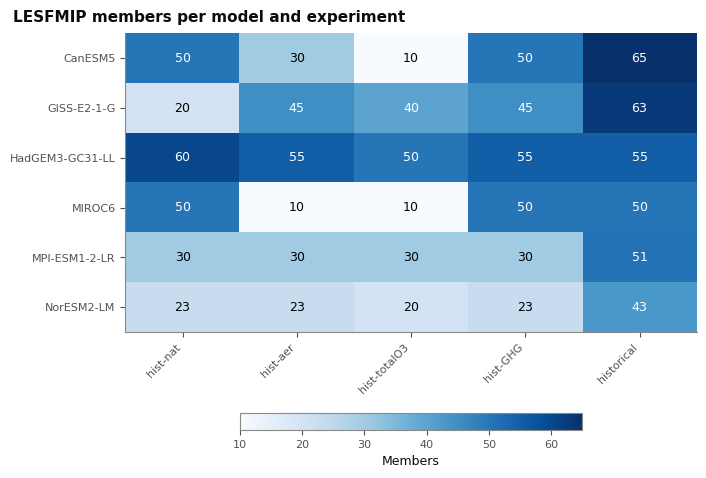

In [18]:
#(t): The members: each model (rows) and experiment (columns), grey where there are none
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=1, n_cols=1, n_legends=0, n_colorbars=1,
                                                  panel_width=0.9 * member_counts_df.shape[1] + 0.5,
                                                  panel_height=0.4 * member_counts_df.shape[0] + 0.3, left_margin=1.8),
                 layout='constrained')
axes = fig.add_gridspec(1, 1).subplots(squeeze=False)
counts_image = methods.plot_member_counts(member_counts_df, ax=axes[0, 0])
fig.colorbar(counts_image, ax=axes, location='bottom', shrink=0.6, label='Members')
fig.suptitle('LESFMIP members per model and experiment', x=0.01, ha='left');

In [19]:
lesfmip_season_tree

<xarray.DataTree>
Group: /
├── Group: /GISS-E2-1-G
│   ├── Group: /GISS-E2-1-G/historical
│   │       Dimensions:  (member: 63, lat: 20, lon: 144, year: 164, season: 4)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * member   (member) object 504B 'r10i1p1f1' 'r10i1p1f2' ... 'r9i1p5f1'
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season) float32 476MB dask.array<chunksize=(63, 4, 144, 164, 4), meta=np.ndarray>
│   ├── Group: /GISS-E2-1-G/hist-GHG
│   │       Dimensions:  (member: 45, lat: 20, lon: 144, year: 164, season: 4)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * member   (member) object 360B 'r10i1p1f2' 'r10i1p3f1' ... 'r9i1p3f1'
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season) float32 340MB dask.array<chunksize=(45, 4, 144, 164, 4), meta=np.ndarray>
│   ├── Group: /GISS-E2-1-G/hist-nat
│   │       Dimensions:  (member: 20, lat: 20, lon: 144, year: 164, season: 4)
│   │       Coordinates:
│   │         * member   (member) object 160B 'r10i1p1f3' 'r1i1p1f2' ... 'r9i1p1f3'
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season) float32 151MB dask.array<chunksize=(20, 4, 144, 164, 4), meta=np.ndarray>
│   ├── Group: /GISS-E2-1-G/hist-aer
│   │       Dimensions:  (member: 45, lat: 20, lon: 144, year: 164, season: 4)
│   │       Coordinates:
│   │         * member   (member) object 360B 'r10i1p1f2' 'r10i1p3f1' ... 'r9i1p3f1'
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season) float32 340MB dask.array<chunksize=(45, 4, 144, 164, 4), meta=np.ndarray>
│   └── Group: /GISS-E2-1-G/hist-totalO3
│           Dimensions:  (member: 40, lat: 20, lon: 144, year: 164, season: 4)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * member   (member) object 320B 'r10i1p1f2' 'r10i1p3f1' ... 'r9i1p3f1'
│             * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│           Data variables:
│               tas      (member, lat, lon, year, season) float32 302MB dask.array<chunksize=(40, 4, 144, 164, 4), meta=np.ndarray>
├── Group: /CanESM5
│   ├── Group: /CanESM5/hist-nat
│   │       Dimensions:  (member: 50, lat: 20, lon: 144, year: 164, season: 4)
│   │       Coordinates:
│   │         * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │         * lat      (lat) float64 160B -87.5 -85.0 -

In [20]:
lesfmip_season_tree['CanESM5'].isel(member=0)

<xarray.DataTree 'CanESM5'>
Group: /
├── Group: /hist-nat
│       Dimensions:  (lat: 20, lon: 144, year: 164, season: 4)
│       Coordinates:
│           member   <U9 36B 'r10i1p1f1'
│         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│       Data variables:
│           tas      (lat, lon, year, season) float32 8MB dask.array<chunksize=(4, 144, 164, 4), meta=np.ndarray>
├── Group: /hist-totalO3
│       Dimensions:  (lat: 20, lon: 144, year: 164, season: 4)
│       Coordinates:
│         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│           member   <U9 36B 'r10i1p1f1'
│         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│       Data variables:
│           tas      (lat, lon, year, season) float32 8MB dask.array<chunksize=(4, 144, 164, 4), meta=np.ndarray>
├── Group: /historical
│       Dimensions:  (lat: 20, lon: 144, year: 164, season: 4)
│       Coordinates:
│           member   <U9 36B 'r10i1p1f1'
│         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│       Data variables:
│           tas      (lat, lon, year, season) float32 8MB dask.array<chunksize=(4, 144, 164, 4), meta=np.ndarray>
├── Group: /hist-aer
│       Dimensions:  (lat: 20, lon: 144, year: 164, season: 4)
│       Coordinates:
│           member   <U9 36B 'r10i1p1f1'
│         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│       Data variables:
│           tas      (lat, lon, year, season) float32 8MB dask.array<chunksize=(4, 144, 164, 4), meta=np.ndarray>
└── Group: /hist-GHG
        Dimensions:  (lat: 20, lon: 144, year: 164, season: 4)
        Coordinates:
          * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
            member   <U9 36B 'r10i1p1f1'
          * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
          * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
          * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
        Data variables:
            tas      (lat, lon, year, season) float32 8MB dask.array<chunksize=(4, 144, 164, 4), meta=np.ndarray>

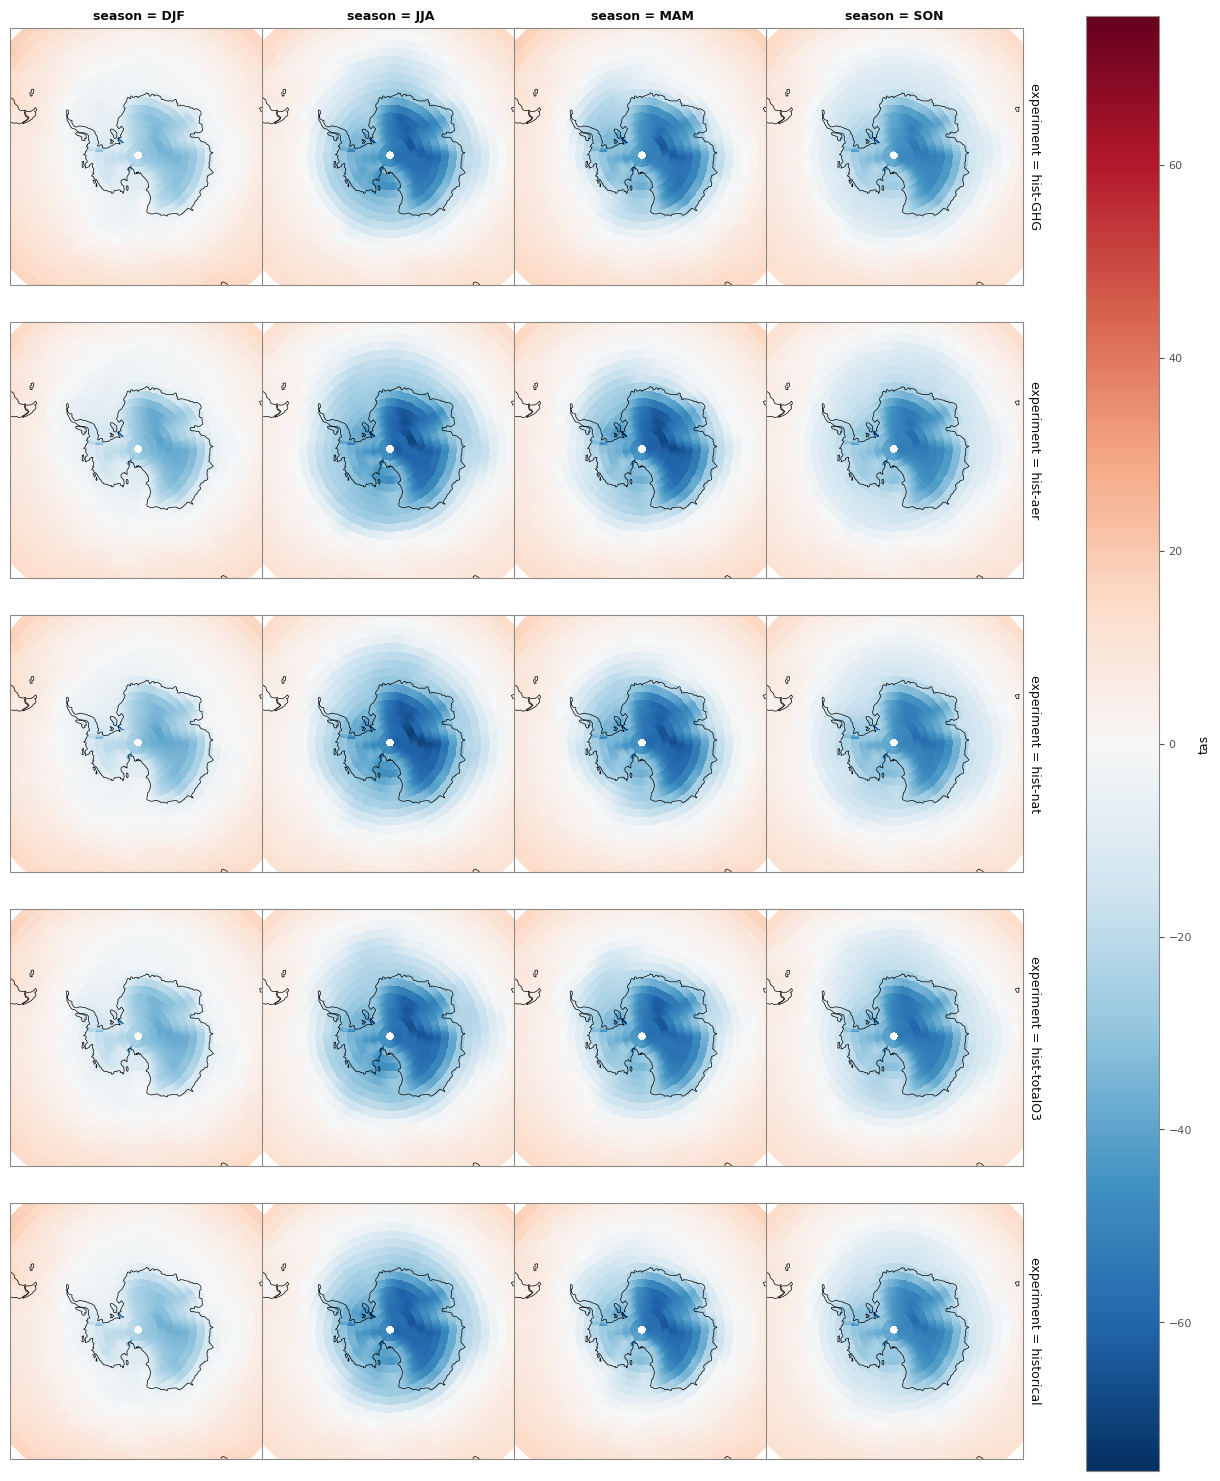

In [21]:
fg = datatree.tree_to_dataset(
    lesfmip_season_tree['CanESM5'].isel(member=0, year=-1),
    dims=['experiment'],
).tas.plot(
    col='season',
    row='experiment',
    subplot_kws={'projection': ccrs.SouthPolarStereo()},
    transform=ccrs.PlateCarree(),
)

for ax in fg.axs.flat:
    ax.set_extent([-180, 180, -90, -50], crs=ccrs.PlateCarree())
    ax.coastlines(linewidth=0.5)

In [22]:
#(t): Where this notebook saves its results
RESULTS_DIR

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full')

In [23]:
#(t): One node in full: a Dataset on (member, lat, lon, year, season)
lesfmip_season_tree[DEMO_MODEL][DEMO_EXPERIMENT].to_dataset()

<xarray.Dataset> Size: 491MB
Dimensions:  (member: 65, lat: 20, lon: 144, year: 164, season: 4)
Coordinates:
  * member   (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
  * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
  * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
  * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
Data variables:
    tas      (member, lat, lon, year, season) float32 491MB dask.array<chunksize=(65, 4, 144, 164, 4), meta=np.ndarray>

## First Look

Every member of each experiment at the demonstration point, for one model. hist-nat (green) has only natural forcing (solar and volcanic), so its spread is what the climate does on its own; every other experiment is compared with it.

First the two ensembles every method figure below starts from: one season at the demonstration point, `DEMO_EXPERIMENT` and hist-nat, each on (member, year).

In [24]:
#(t): One model at the demonstration point, every experiment and season, loaded into memory
demo_tree = lesfmip_season_tree[DEMO_MODEL].sel(**DEMO_LATLON).load()

In [25]:
#(t): The two ensembles every method figure below starts from, one season on (member, year): DEMO_EXPERIMENT
demo_experiment_da = demo_tree[DEMO_EXPERIMENT][VARIABLE.name].sel(season=DEMO_POINT['season'])

In [26]:
#(t): and hist-nat
demo_histnat_da = demo_tree['hist-nat'][VARIABLE.name].sel(season=DEMO_POINT['season'])

In [27]:
#(t): The final WINDOW years of both, on (member, year): what the tests below compare. DEMO_EXPERIMENT's
demo_experiment_final_da = demo_experiment_da.isel(year=slice(-WINDOW, None))
demo_experiment_final_da

<xarray.DataArray 'tas' (member: 65, year: 21)> Size: 5kB
-4.085 -3.57 -3.189 -3.098 -5.389 -1.828 ... -2.439 -6.07 -2.589 -3.868 -4.345
Coordinates:
  * member   (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
  * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'

In [28]:
#(t): and hist-nat's
demo_histnat_final_da = demo_histnat_da.isel(year=slice(-WINDOW, None))
demo_histnat_final_da

<xarray.DataArray 'tas' (member: 50, year: 21)> Size: 4kB
-4.043 -3.745 -3.426 -6.0 -6.079 -4.988 ... -7.633 -5.49 -5.762 -5.217 -4.376
Coordinates:
  * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
    lat      float64 8B -75.0
    lon      float64 8B -180.0
    season   <U3 12B 'DJF'
  * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013

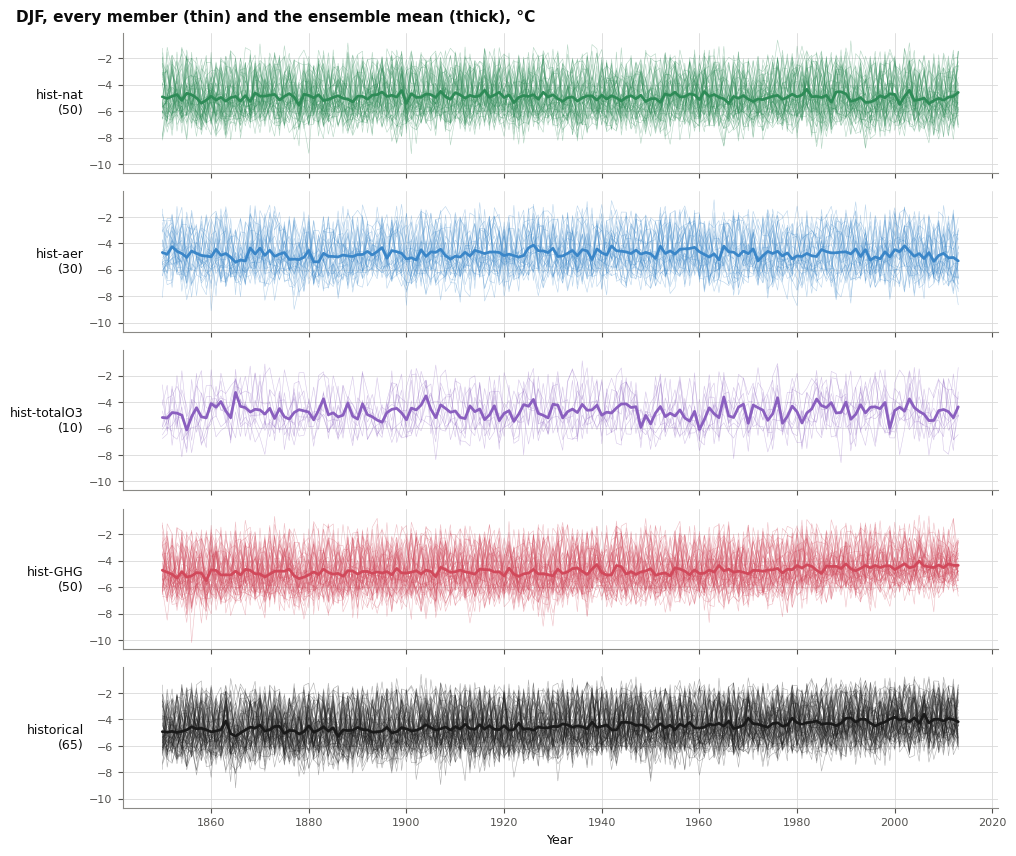

In [29]:
#(t): Every member (thin) and the ensemble mean (thick) of each experiment at the point, in its season: one row each,
#(t): the number of members beside it
demo_experiments = [e for e in config.MAIN_EXPERIMENTS if e in demo_tree.children]
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=len(demo_experiments), n_cols=1, n_legends=0,
                                                  panel_width=8.5, panel_height=1.0, left_margin=1.4),
                 layout='constrained')
axes = fig.add_gridspec(len(demo_experiments), 1).subplots(sharex=True, sharey=True, squeeze=False)
for ax, experiment in zip(axes[:, 0], demo_experiments):
    experiment_members_da = demo_tree[experiment][VARIABLE.name].sel(season=DEMO_POINT['season'])
    charts.plot_lines(experiment_members_da, 'year', ax=ax, color=FORCING_COLORS[experiment], linewidth=0.4, alpha=0.35)
    charts.plot_lines(experiment_members_da.mean('member'), 'year', ax=ax, color=FORCING_COLORS[experiment],
                      linewidth=2)
    ax.set_ylabel(f"{experiment}\n({experiment_members_da.sizes['member']})", rotation=0, ha='right', va='center')
axes[-1, 0].set_xlabel('Year')
fig.suptitle(f"{DEMO_POINT['season']}, every member (thin) and the ensemble mean (thick), {VARIABLE.units}", x=0.01,
             ha='left');

## SAM Phases

Every section with a **By SAM phase** subsection (here 2, the width, and 4, the tails; section 1 of notebook calc_02b, the mean; sections 2 and 3 of calc_02c, the probability ratios) redoes its result with the seasons of one phase of the Southern Annular Mode alone. The index is opened, and each season given its phase, here, and the phases are saved for calc_02b and calc_02c: run **one** of the next two sections, as for the data above.

**The index.** LEADER-EPESC working group 1's monthly SAM index of every LESFMIP member (notebook calc_01's `SAM_RAW_DIR`, the files `archive/draft_current_DAILY.ipynb` opened), seasonally averaged by notebook calc_01 (section 6). It is the zonal-mean index of Gong & Wang (1999): the difference between standardised zonal means at 40°S and 65°S, positive when the westerlies are strong and shifted south.

**The phases.** Each season of each member falls in one phase by its index $S$, against hist-nat's terciles $S_{1/3}$ and $S_{2/3}$ over the final $L$ years (its members and years pooled, for each model and season):

$$
\text{negative: } S < S_{1/3}, \qquad \text{neutral: } S_{1/3} \le S \le S_{2/3}, \qquad \text{positive: } S > S_{2/3}.
$$

The same thresholds serve every experiment of a model, so hist-nat has a third of its seasons in each phase, and an experiment whose SAM has shifted has more in one of them. In each phase, a result compares the experiment's seasons with hist-nat's in the same state of the SAM.

### Sample data

The sample has no SAM index, so a made-up one stands in (`sam.synthetic_index`): random noise with a summer trend in historical and hist-totalO3. It only lets the steps below run; nothing found with it means anything.

In [30]:
#(t): A synthetic index with the sample's members, years and seasons (NOT data)
sam_season_tree = sam.synthetic_index(lesfmip_season_tree, seed=0)

### Full data

The seasonal index notebook calc_01 (section 6) saved in `SCRATCH_DIR`.

In [31]:
#(t): The seasonal SAM index notebook calc_01 saved
sam_season_path = SCRATCH_DIR / 'seasonal' / 'lesfmip_sam.zarr'
sam_season_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/seasonal/lesfmip_sam.zarr')

In [32]:
sam_season_tree = xr.open_datatree(sam_season_path, engine='zarr').load()
sam_season_tree

<xarray.DataTree>
Group: /
├── Group: /NorESM2-LM
│   ├── Group: /NorESM2-LM/hist-totalO3
│   │       Dimensions:  (year: 164, member: 20, season: 4)
│   │       Coordinates:
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * member   (member) object 160B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│   │       Data variables:
│   │           sam      (member, year, season) float64 105kB 1.13 0.3412 ... 0.1169 0.243
│   ├── Group: /NorESM2-LM/hist-aer
│   │       Dimensions:  (season: 4, member: 23, year: 164)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * member   (member) object 184B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │       Data variables:
│   │           sam      (member, year, season) float64 121kB -0.01399 -0.7896 ... 0.02156
│   ├── Group: /NorESM2-LM/hist-nat
│   │       Dimensions:  (member: 23, year: 164, season: 4)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * member   (member) object 184B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │       Data variables:
│   │           sam      (member, year, season) float64 121kB -0.2622 -0.94 ... -0.8976
│   ├── Group: /NorESM2-LM/historical
│   │       Dimensions:  (season: 4, member: 40, year: 164)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * member   (member) object 320B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │       Data variables:
│   │           sam      (member, year, season) float64 210kB 0.1363 -0.6822 ... 0.9998
│   └── Group: /NorESM2-LM/hist-GHG
│           Dimensions:  (member: 23, season: 4, year: 164)
│           Coordinates:
│             * member   (member) object 184B 'r10i1p1f1' 'r11i1p1f1' ... 'r9i1p1f1'
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│           Data variables:
│               sam      (member, year, season) float64 121kB 0.25 0.05513 ... -0.09388
├── Group: /CanESM5
│   ├── Group: /CanESM5/hist-nat
│   │       Dimensions:  (season: 4, year: 164, member: 50)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │       Data variables:
│   │           sam      (member, year, season) float64 262kB 0.9527 0.2381 ... 0.5293
│   ├── Group: /CanESM5/historical
│   │       Dimensions:  (season: 4, year: 164, member: 65)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * member   (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │       Data variables:
│   │           sam      (member, year, season) float64 341kB -0.1312 -0.009562 ... 0.4939
│   ├── Group: /CanESM5/hist-aer
│   │       Dimensions:  (season: 4, member: 30, year: 164)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * member   (member) object 240B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │       Data variables:
│   │           sam      (member, year, season) float64 157kB -0.5724 -0.8401 ... 0.3812
│   ├── Group: /CanESM5/hist-GHG
│   │       Dimensions:  (season:

### Models and experiments with both

The index may not exist for every model and experiment, so every SAM subsection uses only the nodes with both (`sam_both_paths`).

In [33]:
#(t): /<model>/<experiment> of every node with the index, and with temperature
sam_paths = {node.relative_to(sam_season_tree) for node in sam_season_tree.leaves if node.data_vars}
tas_paths = {node.relative_to(lesfmip_season_tree) for node in lesfmip_season_tree.leaves if node.data_vars}
pd.DataFrame({'index': {p: p in sam_paths for p in sorted(sam_paths | tas_paths)},
              VARIABLE.name: {p: p in tas_paths for p in sorted(sam_paths | tas_paths)}})

,index,tas
CanESM5/hist-GHG,True,True
CanESM5/hist-aer,True,True
CanESM5/hist-nat,True,True
CanESM5/hist-totalO3,True,True
CanESM5/historical,True,True
GISS-E2-1-G/hist-GHG,True,True
GISS-E2-1-G/hist-aer,True,True
GISS-E2-1-G/hist-nat,True,True
GISS-E2-1-G/hist-totalO3,True,True
GISS-E2-1-G/historical,True,True


In [34]:
#(t): The ones with both
sam_both_paths = sam_paths & tas_paths
sorted(sam_both_paths)

['CanESM5/hist-GHG',
 'CanESM5/hist-aer',
 'CanESM5/hist-nat',
 'CanESM5/hist-totalO3',
 'CanESM5/historical',
 'GISS-E2-1-G/hist-GHG',
 'GISS-E2-1-G/hist-aer',
 'GISS-E2-1-G/hist-nat',
 'GISS-E2-1-G/hist-totalO3',
 'GISS-E2-1-G/historical',
 'HadGEM3-GC31-LL/hist-GHG',
 'HadGEM3-GC31-LL/hist-aer',
 'HadGEM3-GC31-LL/hist-nat',
 'HadGEM3-GC31-LL/hist-totalO3',
 'HadGEM3-GC31-LL/historical',
 'MIROC6/hist-GHG',
 'MIROC6/hist-aer',
 'MIROC6/hist-nat',
 'MIROC6/hist-totalO3',
 'MIROC6/historical',
 'MPI-ESM1-2-LR/hist-GHG',
 'MPI-ESM1-2-LR/hist-aer',
 'MPI-ESM1-2-LR/hist-nat',
 'MPI-ESM1-2-LR/hist-totalO3',
 'MPI-ESM1-2-LR/historical',
 'NorESM2-LM/hist-GHG',
 'NorESM2-LM/hist-aer',
 'NorESM2-LM/hist-nat',
 'NorESM2-LM/hist-totalO3',
 'NorESM2-LM/historical']

In [35]:
#(t): The index on those nodes only
sam_both_tree = sam_season_tree.filter(lambda node: node.relative_to(sam_season_tree) in sam_both_paths)

### Phases

In [36]:
#(t): The index over the final WINDOW years, the years every result compares
sam_final_tree = sam_both_tree.isel(year=slice(-WINDOW, None))

In [37]:
sam.TERCILES

(0.3333333333333333, 0.6666666666666666)

In [38]:
%%time
#(t): hist-nat's terciles over those years, members and years pooled, on (model, quantile, season)
sam_thresholds_ds = datatree.reduce_to_dataset(sam_final_tree.match('*/hist-nat'),
                                               partial(qc.pooled_quantiles, quantiles=sam.TERCILES))
sam_thresholds_ds = sam_thresholds_ds.sel(experiment='hist-nat', drop=True).compute()

CPU times: user 20.9 ms, sys: 1.01 ms, total: 21.9 ms
Wall time: 21.6 ms


In [39]:
#(t): The same thresholds for every experiment of a model, as a tree shaped like sam_both_tree
sam_thresholds_tree = datatree.dataset_to_tree(sam_thresholds_ds.expand_dims(experiment=config.MAIN_EXPERIMENTS),
                                               like=sam_both_tree)

In [40]:
#(t): Each season's phase: True in one of the three along 'phase', every member, year and season
sam_masks_tree = xr.map_over_datasets(sam.phase_masks, sam_both_tree, sam_thresholds_tree)

In [41]:
#(t): Over the final WINDOW years: the masks every SAM subsection uses
sam_final_masks_tree = sam_masks_tree.isel(year=slice(-WINDOW, None))

In [ ]:
#(t): Saved for notebooks calc_02b and calc_02c, which split their results by the same phases
sam_final_masks_path = RESULTS_DIR / 'sam_final_masks.zarr'
sam_final_masks_tree.to_zarr(sam_final_masks_path, mode='w')
sam_final_masks_path

**How often each phase.** The share of each experiment's seasons in each phase over the final $L$ years: a third each in hist-nat, by construction, and more in the positive phase where a forcing has pushed the SAM up.

In [42]:
%%time
#(t): The share of each experiment's final-years seasons in each phase, on (model, experiment, phase, season)
sam_phase_share_ds = datatree.reduce_to_dataset(sam_final_masks_tree, lambda ds: ds.mean(['member', 'year'])).compute()
sam_phase_share_da = sam_phase_share_ds['in_phase'].rename('phase_share')
sam_phase_share_da

CPU times: user 33.6 ms, sys: 834 μs, total: 34.5 ms
Wall time: 33.8 ms


<xarray.DataArray 'phase_share' (phase: 3, season: 4, model: 6, experiment: 5)> Size: 3kB
0.2381 0.3381 0.3333 0.2429 0.1055 0.0 ... 0.3872 0.3251 0.3333 0.3714 0.4333
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * phase       (phase) <U8 96B 'negative' 'neutral' 'positive'

In [43]:
#(t): DEMO_MODEL's shares, every experiment and season
sam_phase_share_da.sel(model=DEMO_MODEL).to_series().unstack('phase').round(2)

phase                negative  neutral  positive
season experiment                               
DJF    hist-GHG          0.24     0.35      0.41
       hist-aer          0.34     0.36      0.30
       hist-nat          0.33     0.33      0.33
       hist-totalO3      0.24     0.23      0.53
       historical        0.11     0.23      0.66
JJA    hist-GHG          0.29     0.29      0.42
       hist-aer          0.39     0.31      0.30
       hist-nat          0.33     0.33      0.33
       hist-totalO3      0.35     0.34      0.31
       historical        0.29     0.32      0.39
MAM    hist-GHG          0.20     0.32      0.49
       hist-aer          0.39     0.32      0.29
       hist-nat          0.33     0.33      0.33
       hist-totalO3      0.29     0.32      0.39
       historical        0.20     0.31      0.49
SON    hist-GHG          0.29     0.33      0.38
       hist-aer          0.38     0.30      0.32
       hist-nat          0.33     0.33      0.33
       hist-totalO3      0.30     0.35      0.35
       historical        0.23     0.31      0.46

**The forced change of the index.** Each experiment's ensemble-mean index over the final $L$ years minus hist-nat's, as for the mean of temperature (notebook calc_02b, section 1).

In [44]:
#(t): The ensemble-mean index over the final WINDOW years, on (model, experiment, season)
sam_final_mean_ds = datatree.reduce_to_dataset(sam_final_tree, lambda ds: ds.mean(['member', 'year']))

In [45]:
#(t): Each experiment minus hist-nat over the same years
sam_change_ds = sam_final_mean_ds - sam_final_mean_ds.sel(experiment='hist-nat')

In [46]:
sam_change_da = sam_change_ds['sam'].drop_sel(experiment='hist-nat').rename('sam_change')
sam_change_da.to_dataframe().unstack('season').round(2)

sam_change                  
season                              DJF   JJA   MAM   SON
model           experiment                               
CanESM5         hist-GHG           0.18  0.12  0.18  0.11
                hist-aer          -0.05 -0.07 -0.07 -0.04
                hist-totalO3       0.34 -0.08  0.08  0.06
                historical         0.60  0.10  0.19  0.24
GISS-E2-1-G     hist-GHG            NaN   NaN   NaN   NaN
                hist-aer            NaN   NaN   NaN   NaN
                hist-totalO3        NaN   NaN   NaN   NaN
                historical          NaN   NaN   NaN   NaN
HadGEM3-GC31-LL hist-GHG            NaN   NaN   NaN   NaN
                hist-aer            NaN   NaN   NaN   NaN
                hist-totalO3        NaN   NaN   NaN   NaN
                historical          NaN   NaN   NaN   NaN
MIROC6          hist-GHG            NaN   NaN   NaN   NaN
                hist-aer            NaN   NaN   NaN   NaN
                hist-totalO3        NaN   NaN   NaN   NaN
                historical          NaN   NaN   NaN   NaN
MPI-ESM1-2-LR   hist-GHG           0.15  0.14  0.14  0.12
                hist-aer          -0.02 -0.12 -0.04 -0.05
                hist-totalO3       0.24 -0.00  0.03  0.09
                historical         0.43  0.07  0.13  0.18
NorESM2-LM      hist-GHG           0.12  0.12  0.04  0.09
                hist-aer          -0.01  0.07 -0.00 -0.01
                hist-totalO3       0.32  0.01  0.04  0.08
                historical         0.43  0.14  0.08  0.17

In [47]:
#(t): Saved for notebooks plot_03 to plot_06
sam_phase_share_path = RESULTS_DIR / 'sam_phase_share.zarr'
sam_phase_share_da.to_dataset(name='phase_share').to_zarr(sam_phase_share_path, mode='w')
sam_phase_share_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/sam_phase_share.zarr')

In [48]:
#(t): Saved for notebooks plot_03 to plot_06
sam_change_path = RESULTS_DIR / 'sam_change.zarr'
sam_change_da.to_dataset(name='sam_change').to_zarr(sam_change_path, mode='w')
sam_change_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/sam_change.zarr')

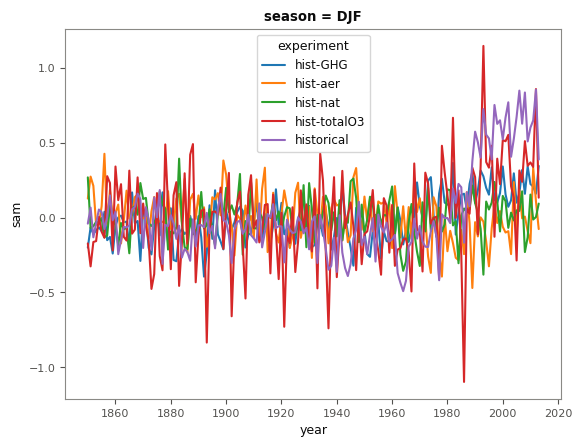

In [49]:
#(t): Quick look: DEMO_MODEL's ensemble-mean index, every experiment, DJF
datatree.tree_to_dataset(sam_both_tree[DEMO_MODEL].mean('member'), dims=['experiment'])['sam'].sel(season='DJF').plot(
    x='year', hue='experiment');

**At the demonstration point.** The index of hist-nat and `DEMO_EXPERIMENT` over the final years in `DEMO_POINT`'s season, cut at hist-nat's terciles, and the temperature of each phase's seasons.

In [50]:
#(t): hist-nat's index over the final years in DEMO_POINT's season, on (member, year)
demo_sam_histnat_da = sam_final_tree[DEMO_MODEL]['hist-nat']['sam'].sel(season=DEMO_POINT['season'])
demo_sam_histnat_da

<xarray.DataArray 'sam' (member: 50, year: 21)> Size: 8kB
0.05281 -0.002868 -0.6941 -0.232 1.204 ... 0.2346 1.216 -0.5051 0.05963 0.01566
Coordinates:
    season   <U3 12B 'DJF'
  * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013
  * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
Attributes: (1)

In [51]:
#(t): DEMO_EXPERIMENT's
demo_sam_experiment_da = sam_final_tree[DEMO_MODEL][DEMO_EXPERIMENT]['sam'].sel(season=DEMO_POINT['season'])
demo_sam_experiment_da

<xarray.DataArray 'sam' (member: 65, year: 21)> Size: 11kB
1.144 0.5268 0.9212 0.6319 1.748 0.4211 ... 1.831 0.4806 0.568 -0.7177 0.5646
Coordinates:
    season   <U3 12B 'DJF'
  * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013
  * member   (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
Attributes: (1)

In [52]:
#(t): hist-nat's terciles, on (quantile,)
demo_sam_thresholds_da = sam_thresholds_ds['sam'].sel(model=DEMO_MODEL, season=DEMO_POINT['season'])
demo_sam_thresholds_da

<xarray.DataArray 'sam' (quantile: 2)> Size: 16B
-0.2524 0.4463
Coordinates:
    model     <U7 28B 'CanESM5'
    season    <U3 12B 'DJF'
  * quantile  (quantile) float64 16B 0.3333 0.6667

In [53]:
#(t): hist-nat's temperature at the point in each phase (demo_histnat_final_da: A first look), on (phase, member, year)
demo_phase_histnat_da = sam.by_phase(demo_histnat_final_da,
                                     sam_final_masks_tree[DEMO_MODEL]['hist-nat'].to_dataset().sel(season=DEMO_POINT['season']))
demo_phase_histnat_da

<xarray.DataArray 'tas' (member: 50, year: 21, phase: 3)> Size: 13kB
nan -4.043 nan nan -3.745 nan -3.426 nan ... nan nan -5.217 nan nan -4.376 nan
Coordinates:
  * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
    lat      float64 8B -75.0
    lon      float64 8B -180.0
    season   <U3 12B 'DJF'
  * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013
  * phase    (phase) <U8 96B 'negative' 'neutral' 'positive'

In [54]:
#(t): DEMO_EXPERIMENT's
demo_phase_experiment_da = sam.by_phase(
    demo_experiment_final_da, sam_final_masks_tree[DEMO_MODEL][DEMO_EXPERIMENT].to_dataset().sel(season=DEMO_POINT['season']))
demo_phase_experiment_da

<xarray.DataArray 'tas' (member: 65, year: 21, phase: 3)> Size: 16kB
nan nan -4.085 nan nan -3.57 nan nan ... -2.589 -3.868 nan nan nan nan -4.345
Coordinates:
  * member   (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
  * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'
  * phase    (phase) <U8 96B 'negative' 'neutral' 'positive'

In [55]:
#(t): Quick look: the number of seasons in each phase, and their mean temperature
pd.DataFrame({'seasons, hist-nat': demo_phase_histnat_da.count(['member', 'year']).to_series(),
              f'seasons, {DEMO_EXPERIMENT}': demo_phase_experiment_da.count(['member', 'year']).to_series(),
              'mean, hist-nat': demo_phase_histnat_da.mean(['member', 'year']).to_series(),
              f'mean, {DEMO_EXPERIMENT}': demo_phase_experiment_da.mean(['member', 'year']).to_series()}).round(2)

,"seasons, hist-nat","seasons, historical","mean, hist-nat","mean, historical"
phase,,,,
negative,350,144,-4.99,-4.22
neutral,350,315,-4.90,-4.19
positive,350,906,-5.17,-4.01


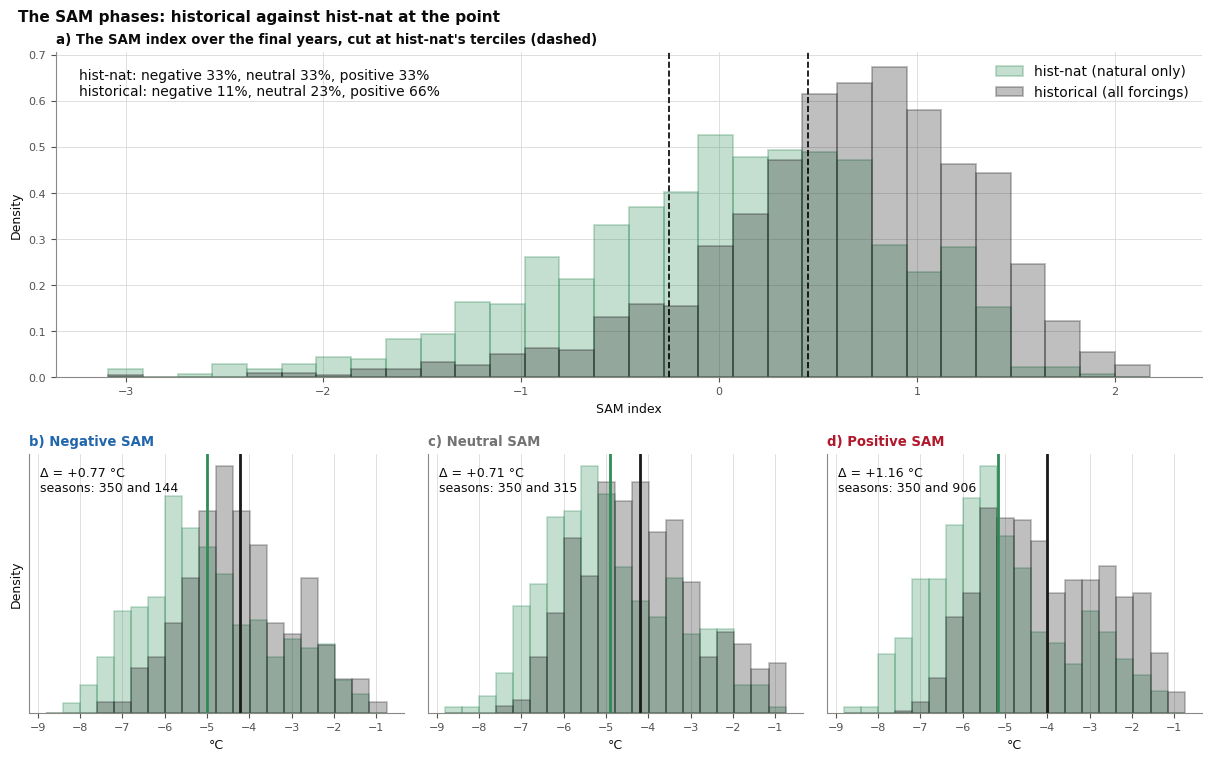

In [56]:
#(t): The SAM phases at the point: a) the index of both ensembles over the final years, cut at hist-nat's terciles
#(t): (dashed); b-d) temperature in each phase's seasons, both ensembles, with their means, on the same bins
sam_phases = list(demo_phase_histnat_da['phase'].values)
phase_edges_arr = np.linspace(float(min(demo_phase_histnat_da.min(), demo_phase_experiment_da.min())),
                              float(max(demo_phase_histnat_da.max(), demo_phase_experiment_da.max())), 21)
fig = plt.figure(figsize=(12, 7.5), layout='constrained')
#(c): The index across the top, a panel per phase under it
grid = fig.add_gridspec(2, 1)
index_ax = fig.add_subplot(grid[0])
phase_axes = grid[1].subgridspec(1, len(sam_phases)).subplots(squeeze=False)
methods.plot_sam_index(demo_sam_histnat_da, demo_sam_experiment_da, demo_sam_thresholds_da, DEMO_EXPERIMENT,
                       ax=index_ax)
index_ax.set_title("a) The SAM index over the final years, cut at hist-nat's terciles (dashed)", loc='left')
index_ax.set_xlabel('SAM index')
index_ax.set_ylabel('Density')
for ax, letter, phase in zip(phase_axes[0], 'bcd', sam_phases):
    methods.plot_phase_temperatures(demo_phase_histnat_da.sel(phase=phase), demo_phase_experiment_da.sel(phase=phase),
                                    DEMO_EXPERIMENT, units=VARIABLE.units, edges=phase_edges_arr, ax=ax)
    ax.set_title(f'{letter}) {phase.capitalize()} SAM', loc='left', color=methods.PHASE_COLORS[phase])
    ax.set_xlabel(VARIABLE.units)
phase_axes[0, 0].set_ylabel('Density')
fig.suptitle(f'The SAM phases: {DEMO_EXPERIMENT} against hist-nat at the point', x=0.01, ha='left');

## 1. Quantile Change Relative to hist-nat

**Rolling quantiles.** For each year $t$, every member's values in the $L$ years centred on $t$ are pooled and their quantiles taken:

$$
Q_p(t) = Q_p\left(\{\,x_{m,y} : m = 1,\ldots,M,\ |y - t| \le \tfrac{L-1}{2}\,\}\right),
$$

so each comes from $M \times L$ values (over a thousand for 50 members). Windows that run off either end of the record are left out.

**Smoothing.** The rolling quantiles are then smoothed with LOWESS (local linear regression, 81-year span), giving $\tilde{Q}_p(t)$.

**The change.** Each experiment's smoothed quantiles minus hist-nat's quantiles over its whole record (members and years pooled):

$$
\Delta Q_p(t) = \tilde{Q}_p^{\,\mathrm{exp}}(t) - Q_p^{\,\mathrm{nat}}.
$$

The change in the width of the distribution between two quantiles is then the difference of their changes. Taking anomalies first gives the same thing:

$$
\Delta W(t) = \Delta Q_{95}(t) - \Delta Q_{05}(t) = \left(\tilde{Q}_{95}^{\,\mathrm{exp}} - \tilde{Q}_{05}^{\,\mathrm{exp}}\right) - \left(Q_{95}^{\,\mathrm{nat}} - Q_{05}^{\,\mathrm{nat}}\right),
$$

which is the same as differencing the widths (as in Bracegirdle et al., 2024).

How one point of a rolling quantile is made, at the demonstration point:

In [57]:
#(t): The rolling quantiles of DEMO_EXPERIMENT at the point, on (quantile, year): for each year, every member's values
#(t): in the WINDOW years centred on it pooled
demo_rolling_da = qc.centred_rolling_quantiles(demo_experiment_da, window=WINDOW, quantiles=QUANTILES)
demo_rolling_da

<xarray.DataArray 'tas' (quantile: 7, year: 164)> Size: 9kB
nan nan nan nan nan nan nan nan nan nan ... nan nan nan nan nan nan nan nan nan
Coordinates:
  * year      (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
    lon       float64 8B -180.0
    lat       float64 8B -75.0
    season    <U3 12B 'DJF'
  * quantile  (quantile) float64 56B 0.01 0.05 0.1 0.5 0.9 0.95 0.99

In [58]:
#(t): Check by hand: the window centred on 1960 runs from 1960 - WINDOW // 2 to 1960 + WINDOW // 2, every member
window_arr = demo_experiment_da.sel(year=slice(1960 - WINDOW // 2, 1960 + WINDOW // 2)).values.ravel()
window_arr.shape

(1365,)

In [59]:
#(t): numpy's quantiles of those values, next to the rolling quantiles of 1960
pd.DataFrame({'np.nanquantile': np.nanquantile(window_arr, QUANTILES),
              'centred_rolling_quantiles': demo_rolling_da.sel(year=1960).values},
             index=pd.Index(QUANTILES, name='quantile'))

,np.nanquantile,centred_rolling_quantiles
quantile,,
0.01,-7.401801,-7.401801
0.05,-6.509661,-6.509661
0.10,-6.244239,-6.244239
0.50,-4.737375,-4.737375
0.90,-2.293840,-2.293840
0.95,-1.874383,-1.874383
0.99,-1.436159,-1.436159


In [60]:
#(t): Check: the years with a complete window. The first and last WINDOW // 2 years have none, so they are NaN
demo_rolling_da.dropna('year').year

<xarray.DataArray 'year' (year: 144)> Size: 1kB
1860 1861 1862 1863 1864 1865 1866 1867 ... 1997 1998 1999 2000 2001 2002 2003
Coordinates:
  * year     (year) int64 1kB 1860 1861 1862 1863 1864 ... 2000 2001 2002 2003
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'

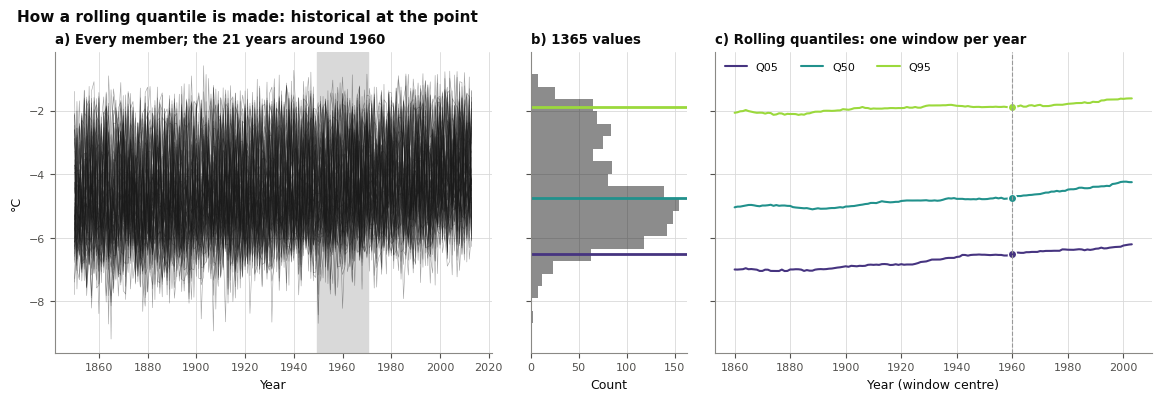

In [61]:
#(t): How one point of a rolling quantile is made: a) every member, the WINDOW years around 1960 shaded; b) their values
#(t): pooled, with Q05, Q50 and Q95; c) the rolling quantiles through time, 1960 marked. All on one y axis
fig = plt.figure(figsize=(11.5, 3.9), layout='constrained')
#(c): Three panels, the middle one narrow
members_ax, values_ax, rolling_ax = fig.add_gridspec(1, 3, width_ratios=[4.2, 1.5, 4.2]).subplots()
methods.plot_window(demo_experiment_da, 1960, WINDOW, color=FORCING_COLORS[DEMO_EXPERIMENT], ax=members_ax)
methods.plot_window_values(demo_experiment_da, 1960, WINDOW, color=FORCING_COLORS[DEMO_EXPERIMENT],
                           ax=values_ax)
methods.plot_rolling_quantiles(demo_rolling_da, 1960, ax=rolling_ax)
#(c): One y axis for the three
for ax in (values_ax, rolling_ax):
    ax.sharey(members_ax)
    ax.tick_params(axis='y', labelleft=False)
n_window_values = int(demo_experiment_da.sel(year=slice(1960 - WINDOW // 2, 1960 + WINDOW // 2)).notnull().sum())
members_ax.set_title(f'a) Every member; the {WINDOW} years around 1960', loc='left')
members_ax.set_xlabel('Year')
members_ax.set_ylabel(VARIABLE.units)
values_ax.set_title(f'b) {n_window_values} values', loc='left')
values_ax.set_xlabel('Count')
rolling_ax.set_title('c) Rolling quantiles: one window per year', loc='left')
rolling_ax.set_xlabel('Year (window centre)')
fig.suptitle(f'How a rolling quantile is made: {DEMO_EXPERIMENT} at the point', x=0.01, ha='left');

Now everywhere: hist-nat's whole-record quantiles, and the rolling quantiles of every model and experiment (numba, on the cluster), then smoothed.

In [62]:
#(t): hist-nat alone: its node in every model
lesfmip_hist_nat_tree = lesfmip_season_tree.match('*/hist-nat')

In [63]:
%%time
#(t): hist-nat's quantiles over its whole record, members and years pooled
q_histnat_base_ds = datatree.reduce_to_dataset(lesfmip_hist_nat_tree, partial(qc.pooled_quantiles, quantiles=QUANTILES))
q_histnat_base_ds = q_histnat_base_ds.sel(experiment='hist-nat', drop=True).compute()
q_histnat_base_ds

CPU times: user 45.8 ms, sys: 12.5 ms, total: 58.3 ms
Wall time: 2.11 s


<xarray.Dataset> Size: 4MB
Dimensions:   (model: 6, lon: 144, lat: 20, season: 4, quantile: 7)
Coordinates:
  * model     (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * lon       (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * lat       (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * season    (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * quantile  (quantile) float64 56B 0.01 0.05 0.1 0.5 0.9 0.95 0.99
Data variables:
    tas       (lat, lon, season, quantile, model) float64 4MB -29.08 ... 14.84

In [64]:
WINDOW, QUANTILES

(21, array([0.01, 0.05, 0.1 , 0.5 , 0.9 , 0.95, 0.99]))

In [65]:
%%time
#(t): Centred rolling quantiles of every model and experiment: they pool the members, so one Dataset
rolling_quantiles_ds = datatree.reduce_to_dataset(
    lesfmip_season_tree,
    partial(qc.centred_rolling_quantiles, window=WINDOW, quantiles=QUANTILES),
).persist()
wait(rolling_quantiles_ds)
rolling_quantiles_ds

CPU times: user 200 ms, sys: 6.43 ms, total: 207 ms
Wall time: 30.2 s


<xarray.Dataset> Size: 3GB
Dimensions:     (model: 6, experiment: 5, lon: 144, year: 164, season: 4,
                 lat: 20, quantile: 7)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * year        (year) int64 1kB 1850 1851 1852 1853 ... 2010 2011 2012 2013
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * quantile    (quantile) float64 56B 0.01 0.05 0.1 0.5 0.9 0.95 0.99
Data variables:
    tas         (lat, lon, season, quantile, year, model, experiment) float64 3GB dask.array<chunksize=(4, 144, 4, 7, 164, 1, 1), meta=np.ndarray>

In [66]:
%%time
#(t): The rolling quantiles smoothed with LOWESS (81 years)
smooth_quantiles_ds = qc.lowess_matrix_xarray(rolling_quantiles_ds).compute()
smooth_quantiles_ds

CPU times: user 1.51 s, sys: 2.64 s, total: 4.14 s
Wall time: 18.5 s


<xarray.Dataset> Size: 3GB
Dimensions:     (lat: 20, lon: 144, season: 4, quantile: 7, model: 6,
                 experiment: 5, year: 164)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * year        (year) int64 1kB 1850 1851 1852 1853 ... 2010 2011 2012 2013
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * quantile    (quantile) float64 56B 0.01 0.05 0.1 0.5 0.9 0.95 0.99
Data variables:
    tas         (lat, lon, season, quantile, model, experiment, year) float64 3GB ...

In [67]:
smooth_quantiles_ds = smooth_quantiles_ds.dropna(dim='year')
smooth_quantiles_ds

<xarray.Dataset> Size: 3GB
Dimensions:     (lat: 20, lon: 144, season: 4, quantile: 7, model: 6,
                 experiment: 5, year: 144)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * year        (year) int64 1kB 1860 1861 1862 1863 ... 2000 2001 2002 2003
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * quantile    (quantile) float64 56B 0.01 0.05 0.1 0.5 0.9 0.95 0.99
Data variables:
    tas         (lat, lon, season, quantile, model, experiment, year) float64 3GB ...

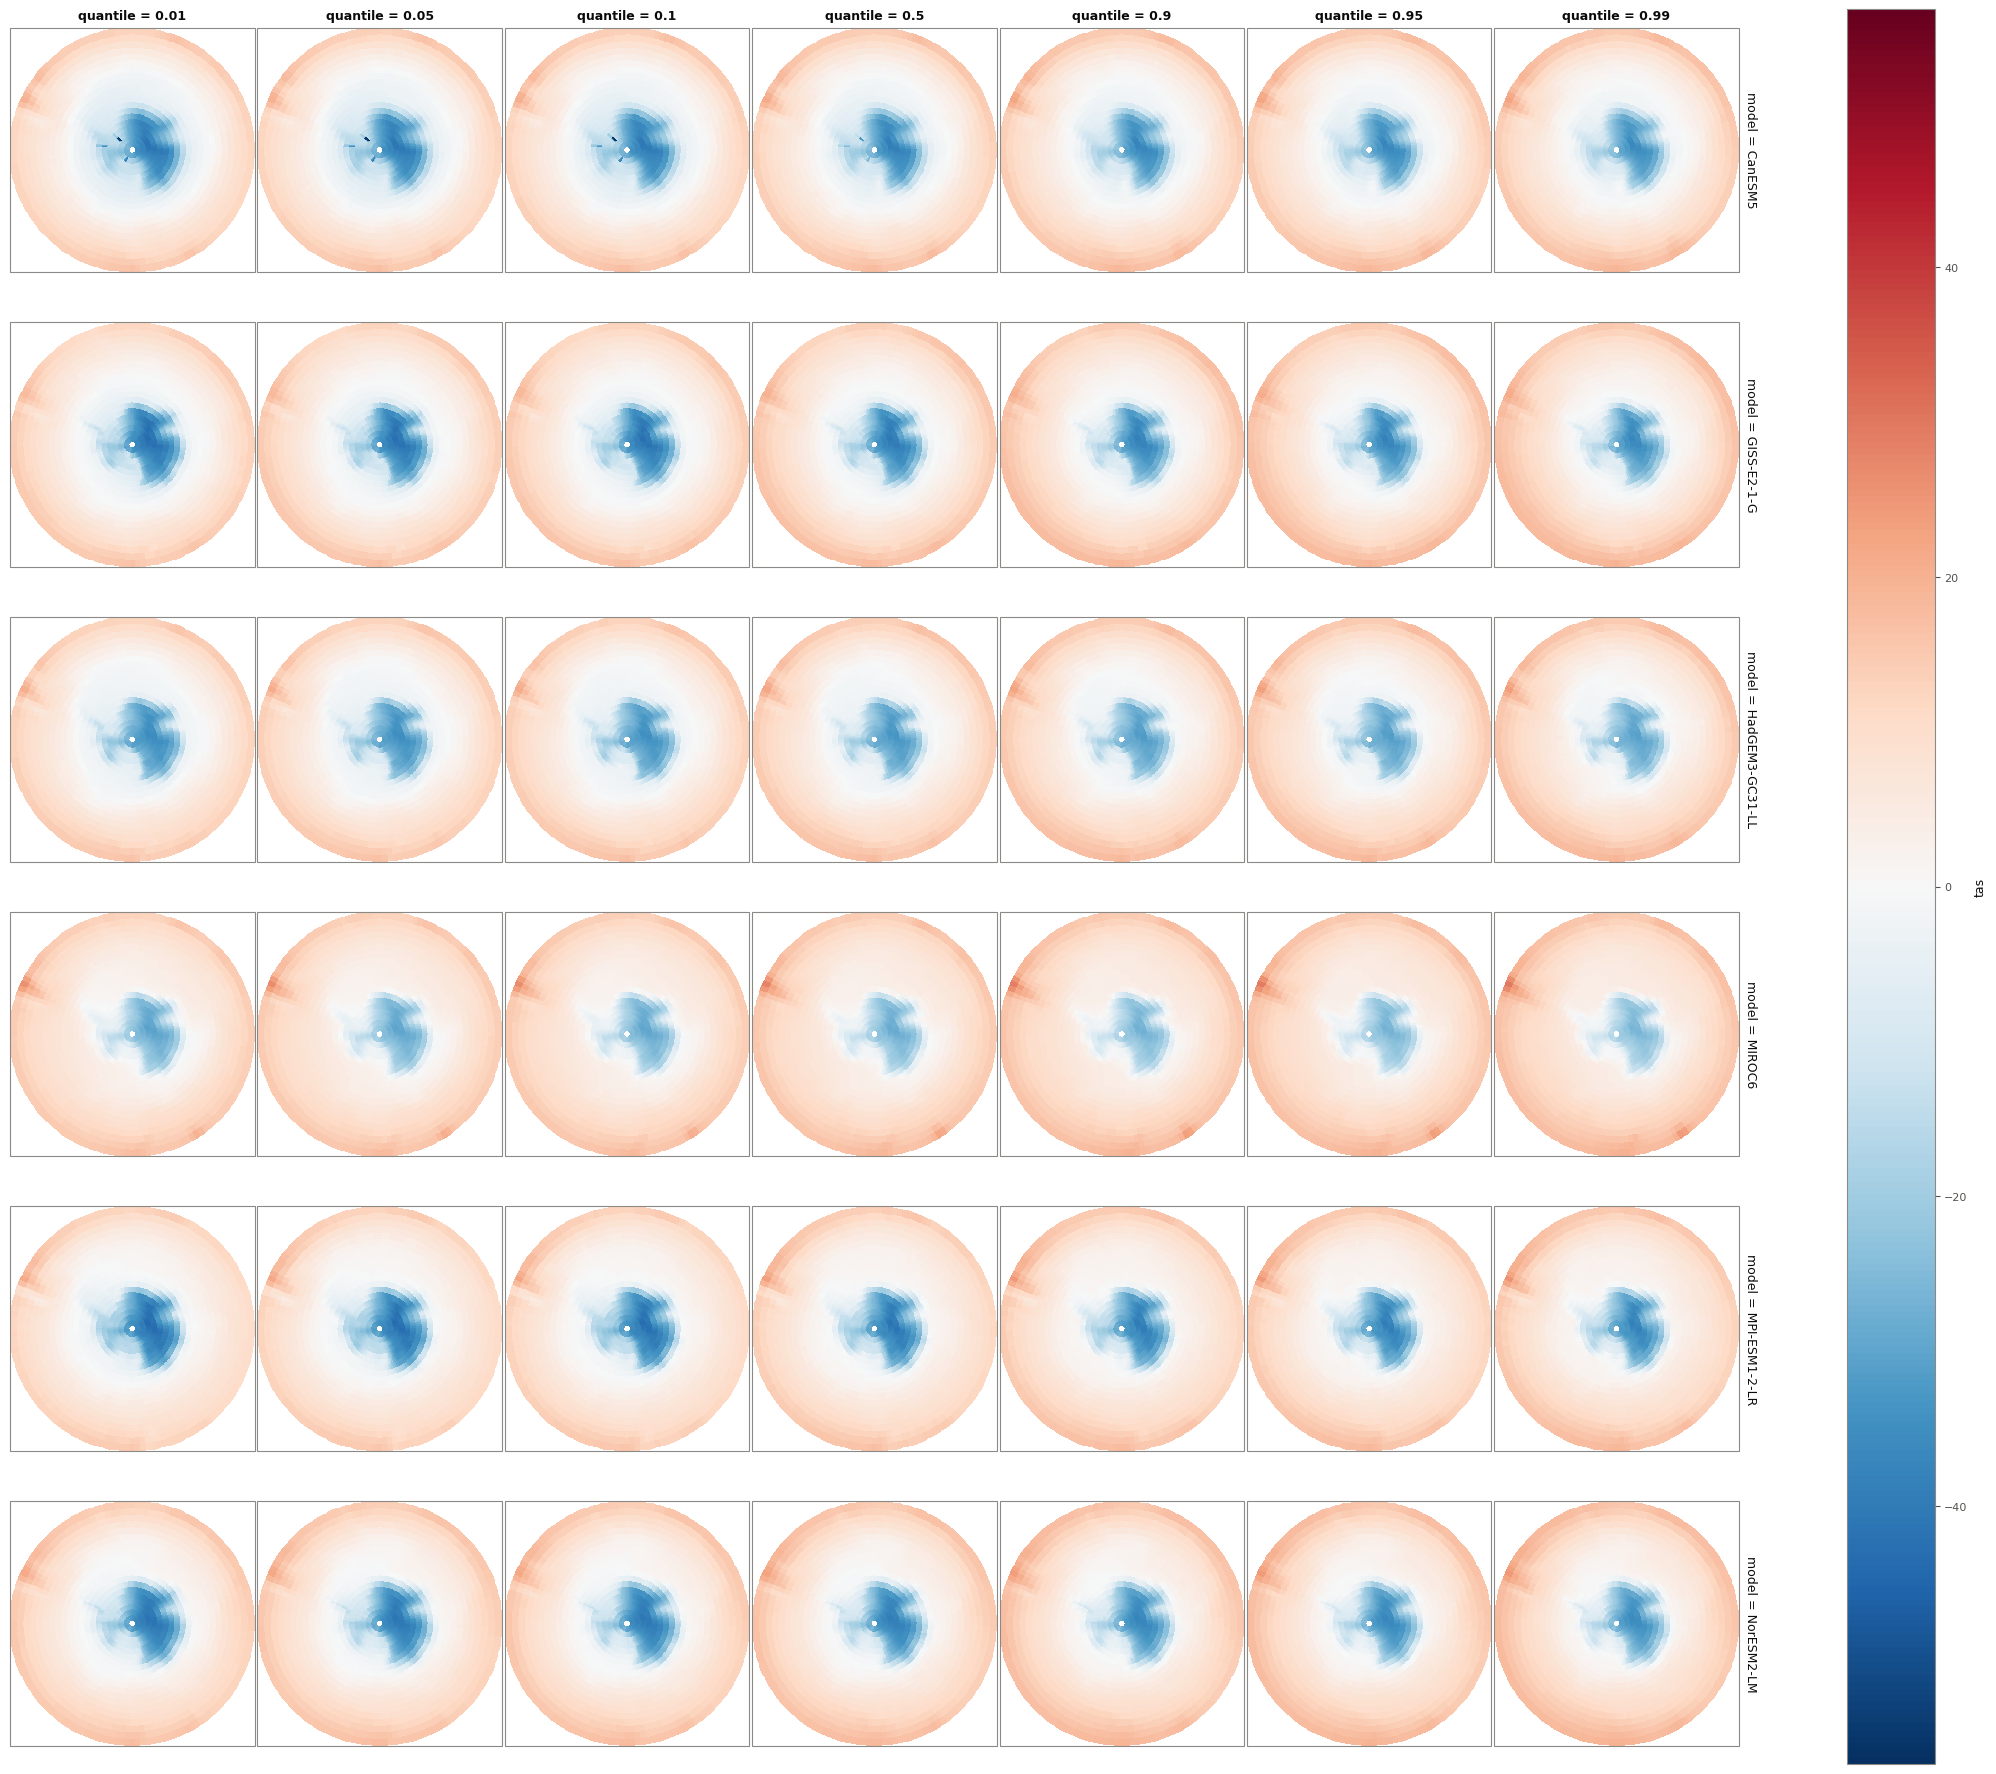

In [68]:
q_histnat_base_ds.tas.sel(season='DJF').plot(col='quantile', row='model',
                                             subplot_kws={'projection': ccrs.SouthPolarStereo()}, transform=ccrs.PlateCarree())

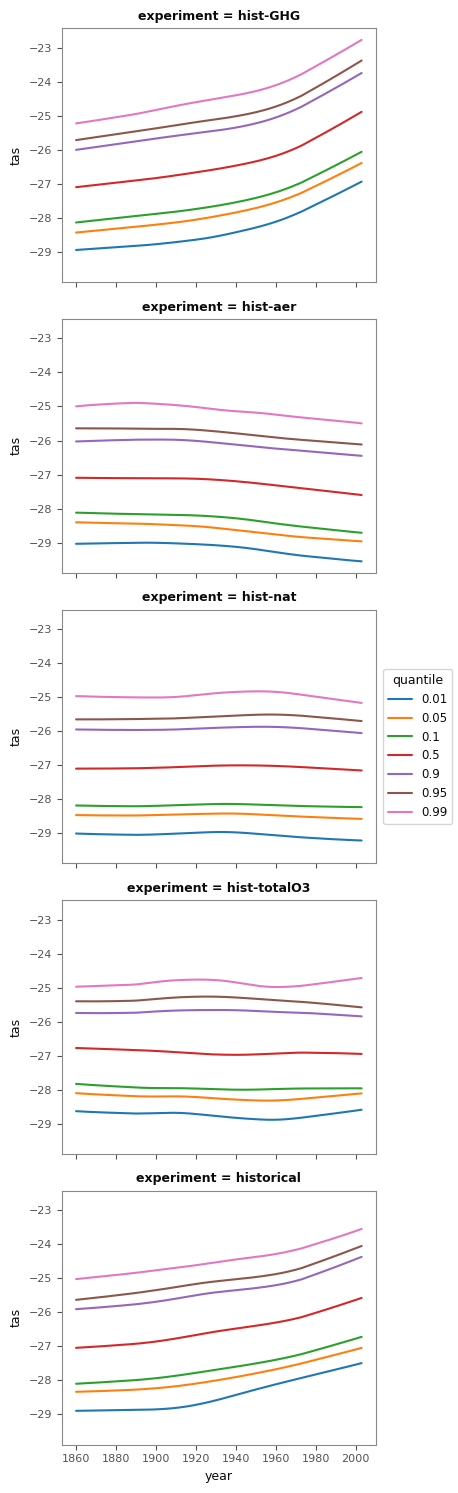

In [69]:
smooth_quantiles_ds.tas.isel(model=0, season=0, lat=0, lon=0).plot(row='experiment', hue='quantile')

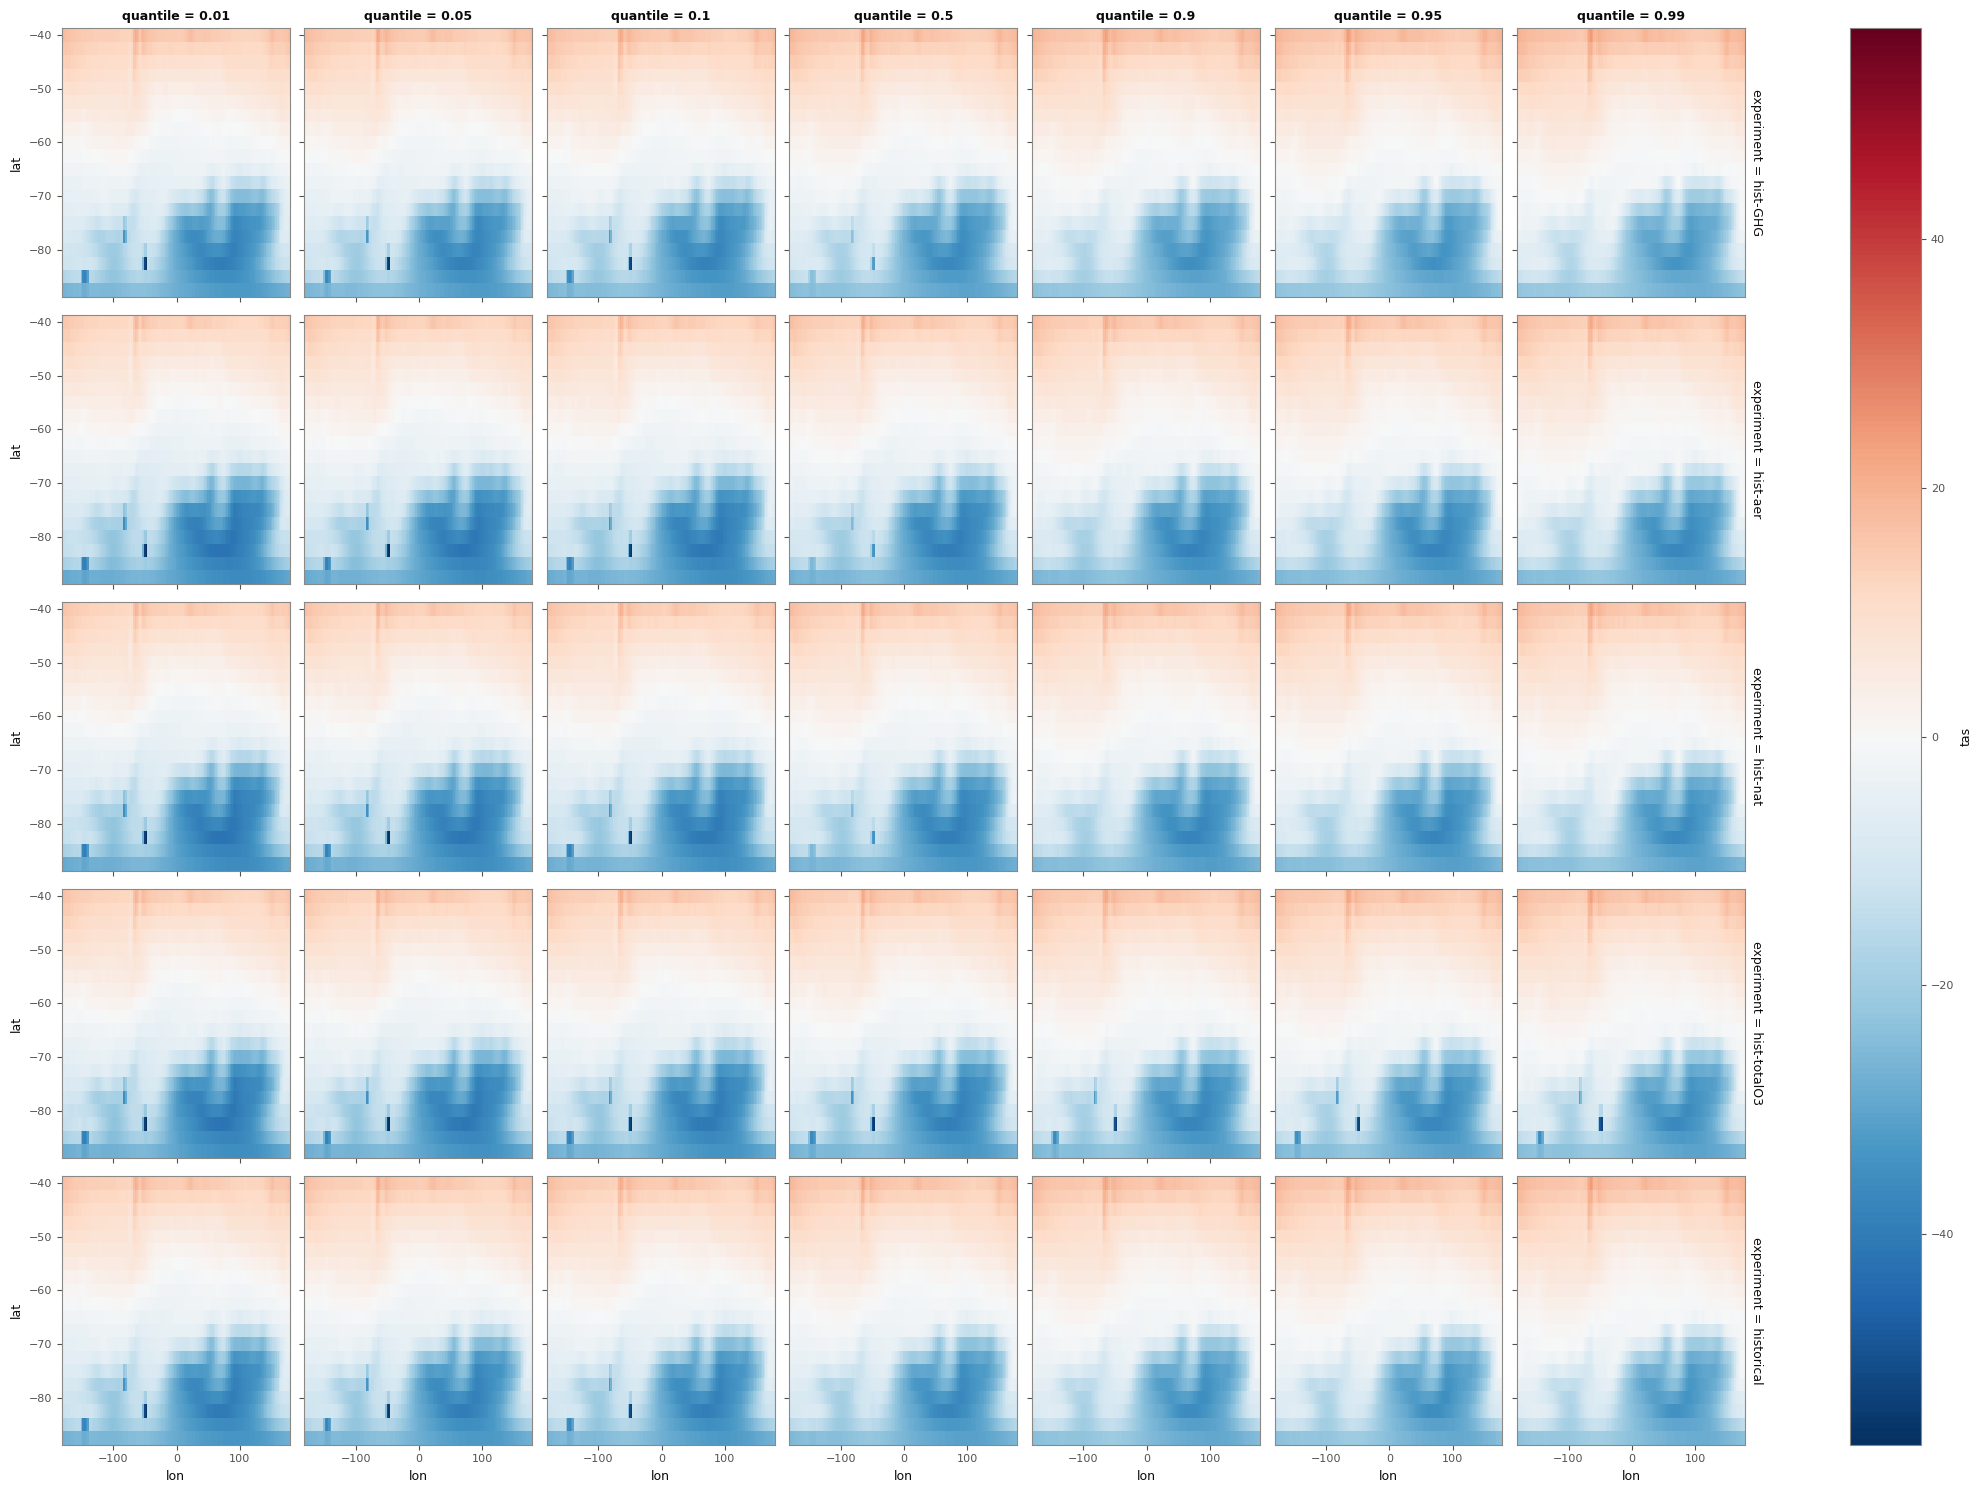

In [70]:
smooth_quantiles_ds.tas.isel(model=0, season=0, year=-1).plot(col='quantile', row='experiment')

In [71]:
q_histnat_base_ds

<xarray.Dataset> Size: 4MB
Dimensions:   (model: 6, lon: 144, lat: 20, season: 4, quantile: 7)
Coordinates:
  * model     (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * lon       (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * lat       (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * season    (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * quantile  (quantile) float64 56B 0.01 0.05 0.1 0.5 0.9 0.95 0.99
Data variables:
    tas       (lat, lon, season, quantile, model) float64 4MB -29.08 ... 14.84

In [72]:
smooth_quantiles_ds

<xarray.Dataset> Size: 3GB
Dimensions:     (lat: 20, lon: 144, season: 4, quantile: 7, model: 6,
                 experiment: 5, year: 144)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * year        (year) int64 1kB 1860 1861 1862 1863 ... 2000 2001 2002 2003
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * quantile    (quantile) float64 56B 0.01 0.05 0.1 0.5 0.9 0.95 0.99
Data variables:
    tas         (lat, lon, season, quantile, model, experiment, year) float64 3GB ...

In [73]:
#(t): Saved for notebooks plot_03 to plot_06
q_histnat_base_path = RESULTS_DIR / 'q_histnat_base.zarr'
q_histnat_base_ds.to_zarr(q_histnat_base_path, mode='w')
q_histnat_base_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/q_histnat_base.zarr')

In [74]:
%%time
#(t): Saved for notebook plot_03; loaded from the cluster first, so it is written in one piece
rolling_quantiles_path = RESULTS_DIR / 'rolling_quantiles.zarr'
rolling_quantiles_ds.load().to_zarr(rolling_quantiles_path, mode='w')
rolling_quantiles_path

CPU times: user 25.7 s, sys: 5.39 s, total: 31.1 s
Wall time: 28.5 s


PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/rolling_quantiles.zarr')

In [75]:
#(t): Saved for notebooks plot_03 to plot_06
smooth_quantiles_path = RESULTS_DIR / 'smooth_quantiles.zarr'
smooth_quantiles_ds.to_zarr(smooth_quantiles_path, mode='w')
smooth_quantiles_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/smooth_quantiles.zarr')

The smoothing, and the change against hist-nat, at the demonstration point. First the point is picked out of the three results, printed and plotted plainly; then the two method figures, which are given exactly these arrays: on the left, thin lines are the rolling quantiles and thick the smoothed ones; on the right, $\Delta Q_{05}$ and $\Delta Q_{95}$, with the change in width as the gap between them.

In [76]:
#(t): The demonstration point picked out of the rolling quantiles, on (experiment, quantile, year)
point_rolling_da = rolling_quantiles_ds[VARIABLE.name].sel(**DEMO_SEL).sel(**DEMO_LATLON)
point_rolling_da

<xarray.DataArray 'tas' (quantile: 7, year: 164, experiment: 5)> Size: 46kB
nan nan nan nan nan nan nan nan nan nan ... nan nan nan nan nan nan nan nan nan
Coordinates:
    model       <U7 28B 'CanESM5'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
    lon         float64 8B -180.0
  * year        (year) int64 1kB 1850 1851 1852 1853 ... 2010 2011 2012 2013
    season      <U3 12B 'DJF'
    lat         float64 8B -75.0
  * quantile    (quantile) float64 56B 0.01 0.05 0.1 0.5 0.9 0.95 0.99

In [77]:
#(t): out of the smoothed ones, on (experiment, quantile, year)
point_smooth_da = smooth_quantiles_ds[VARIABLE.name].sel(**DEMO_SEL).sel(**DEMO_LATLON)

In [78]:
#(t): and out of hist-nat's whole-record quantiles, on (quantile)
point_base_da = q_histnat_base_ds[VARIABLE.name].sel(**DEMO_SEL).sel(**DEMO_LATLON)

In [79]:
#(t): The change: the smoothed quantiles minus hist-nat's whole record, on (experiment, quantile, year)
point_change_da = point_smooth_da - point_base_da

In [80]:
#(t): The numbers in the last year with a complete window: hist-nat's base, the smoothed quantiles, and the change
final_year = int(point_smooth_da.year[config.LAST_FULL_YEAR])
pd.DataFrame({
    'point_base_da': point_base_da.values,
    f'point_smooth_da ({DEMO_EXPERIMENT}, {final_year})': point_smooth_da.sel(experiment=DEMO_EXPERIMENT, year=final_year).values,
    'point_change_da': point_change_da.sel(experiment=DEMO_EXPERIMENT, year=final_year).values,
}, index=pd.Index(point_base_da['quantile'].values, name='quantile')).round(2)

,point_base_da,"point_smooth_da (historical, 1993)",point_change_da
quantile,,,
0.01,-7.83,-6.84,0.99
0.05,-7.10,-6.31,0.79
0.10,-6.75,-5.97,0.78
0.50,-5.20,-4.35,0.84
0.90,-2.66,-2.05,0.61
0.95,-2.17,-1.69,0.47
0.99,-1.52,-1.15,0.37


In [81]:
DEMO_EXPERIMENT, QRANGE_QUANTILES

('historical', (0.05, 0.95))

In [82]:
#(t): The change in the two quantiles of the width test, for DEMO_EXPERIMENT
low_da = point_change_da.sel(experiment=DEMO_EXPERIMENT, quantile=Q_LOW)
high_da = point_change_da.sel(experiment=DEMO_EXPERIMENT, quantile=Q_HIGH)
high_da

<xarray.DataArray 'tas' (year: 144)> Size: 1kB
0.07039 0.0724 0.07446 0.07657 0.07874 ... 0.509 0.515 0.521 0.5271 0.5332
Coordinates:
    model       <U7 28B 'CanESM5'
    experiment  <U10 40B 'historical'
    lon         float64 8B -180.0
  * year        (year) int64 1kB 1860 1861 1862 1863 ... 2000 2001 2002 2003
    season      <U3 12B 'DJF'
    lat         float64 8B -75.0
    quantile    float64 8B 0.95

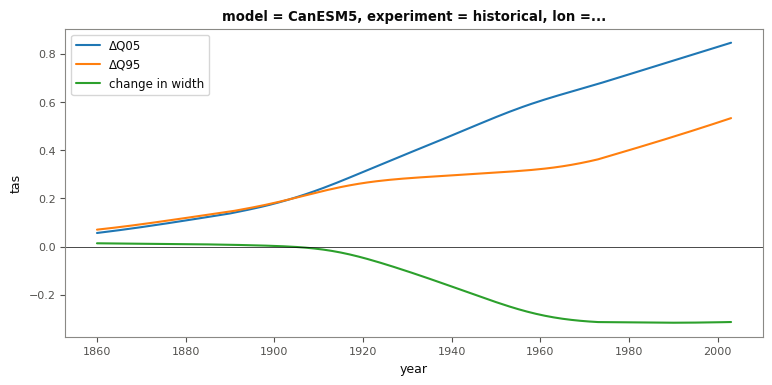

In [83]:
#(t): Quick look: the two, and the change in width between them
fig, ax = plt.subplots(figsize=(9, 4))
low_da.plot(ax=ax, label=f'ΔQ{Q_LOW * 100:02.0f}')
high_da.plot(ax=ax, label=f'ΔQ{Q_HIGH * 100:02.0f}')
(high_da - low_da).plot(ax=ax, label='change in width')
ax.axhline(0, color='k', lw=0.5)
ax.legend();

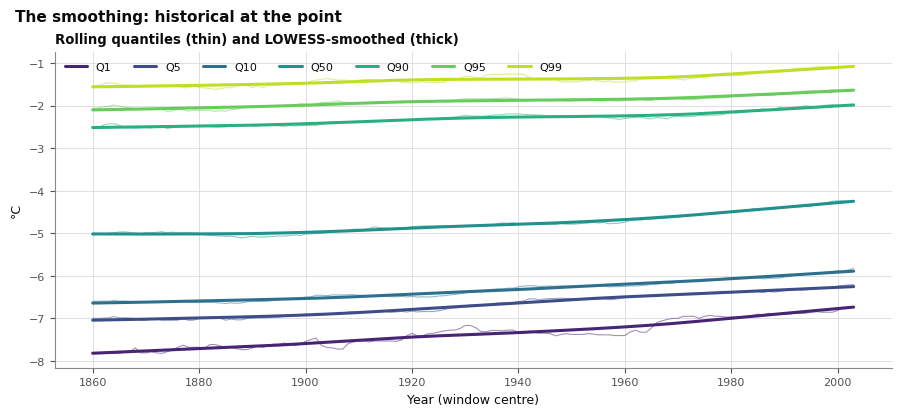

In [84]:
#(t): The rolling quantiles before (thin) and after (thick) LOWESS smoothing, at the point
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=1, n_cols=1, n_legends=0, panel_width=8.0, panel_height=2.8),
                 layout='constrained')
axes = fig.add_gridspec(1, 1).subplots(squeeze=False)
methods.plot_smoothing(point_rolling_da.sel(experiment=DEMO_EXPERIMENT), point_smooth_da.sel(experiment=DEMO_EXPERIMENT),
                       ax=axes[0, 0])
axes[0, 0].set_title('Rolling quantiles (thin) and LOWESS-smoothed (thick)', loc='left')
axes[0, 0].set_xlabel('Year (window centre)')
axes[0, 0].set_ylabel(VARIABLE.units)
fig.suptitle(f'The smoothing: {DEMO_EXPERIMENT} at the point', x=0.01, ha='left');

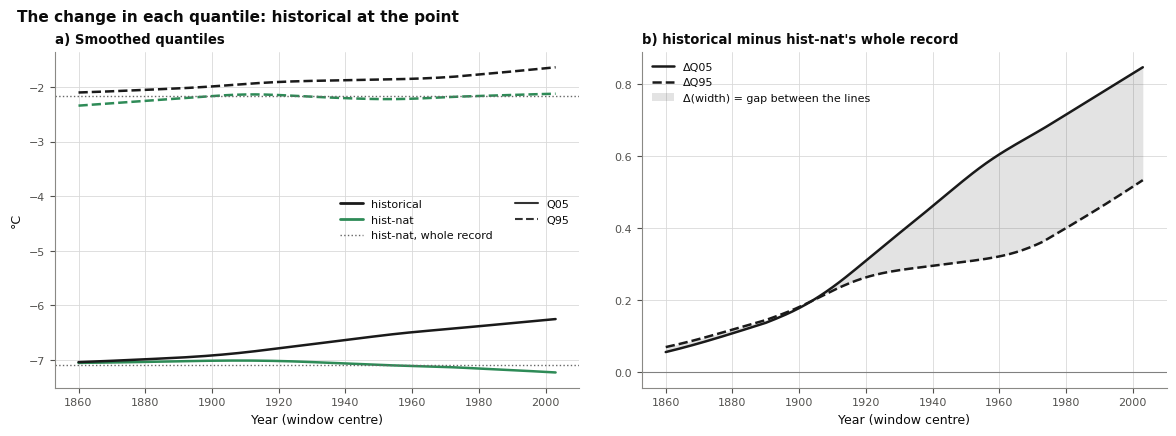

In [85]:
#(t): The change in each quantile: a) the smoothed quantiles of DEMO_EXPERIMENT and hist-nat, hist-nat's whole-record
#(t): quantiles dotted; b) DEMO_EXPERIMENT's minus hist-nat's whole record, the gap between the two the change in width
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=1, n_cols=2, n_legends=0, panel_width=5.0, panel_height=3.0,
                                                  column_gap=0.75), layout='constrained')
axes = fig.add_gridspec(1, 2).subplots(squeeze=False)
methods.plot_smoothed_quantiles(point_smooth_da.sel(experiment=[DEMO_EXPERIMENT, 'hist-nat']), point_base_da,
                                DEMO_EXPERIMENT, quantiles=QRANGE_QUANTILES, ax=axes[0, 0])
methods.plot_quantile_changes(point_smooth_da.sel(experiment=[DEMO_EXPERIMENT, 'hist-nat']), point_base_da,
                              DEMO_EXPERIMENT, quantiles=QRANGE_QUANTILES, ax=axes[0, 1])
axes[0, 0].set_title('a) Smoothed quantiles', loc='left')
axes[0, 0].set_ylabel(VARIABLE.units)
axes[0, 1].set_title(f"b) {DEMO_EXPERIMENT} minus hist-nat's whole record", loc='left')
for ax in axes[0]:
    ax.set_xlabel('Year (window centre)')
fig.suptitle(f'The change in each quantile: {DEMO_EXPERIMENT} at the point', x=0.01, ha='left');

## 2. Change in Width: the hist-nat Bootstrap

**The question.** Has the distribution got wider or narrower, by more than natural variability can produce? The width is $W = Q_{95} - Q_{05}$ of the pooled values (members and years), and the change is the experiment's width over the final $L$ years minus hist-nat's over the same years:

$$
\Delta W_{\mathrm{obs}} = W\left(x^{\mathrm{exp}}_{\text{final } L \text{ years}}\right) - W\left(x^{\mathrm{nat}}_{\text{final } L \text{ years}}\right).
$$

**The test** compares the experiment's width with the widths hist-nat gives on its own over the same years. Trial $k$ draws $n = 10$ different hist-nat members, pools their values over the final $L$ years ($nL = 210$ values) and takes their width:

$$
W_k = W\left(x^{\mathrm{nat}}_{m \in S_k,\ \text{final } L \text{ years}}\right), \qquad k = 1, \ldots, N.
$$

Each $W_k$ is a width that natural variability and a 10-member sample give over those years, with the same volcanoes and sun as the experiment's. The two-sided p-value counts the trials at least as wide, or at least as narrow, as the experiment:

$$
p = \min\left(1,\ \frac{2\,\min\left(1 + \#\{W_k \ge W_{\mathrm{exp}}\},\ 1 + \#\{W_k \le W_{\mathrm{exp}}\}\right)}{N + 1}\right),
$$

and the change is significant where $p < \alpha = 0.05$, i.e. where the experiment's width is outside the trials' central 95%. Nothing is subtracted for the test; $\Delta W_{\mathrm{obs}}$ is what the figures show.

**How well it holds.** The trials are 10 members of hist-nat's own ensemble, so how much they spread depends on how big that ensemble is. On synthetic data with these ensemble sizes and no change at all (where 5% should come out significant), the test called 11–16% significant where hist-nat has 20–23 members (GISS-E2-1-G, NorESM2-LM) or the experiment has 10 (MIROC6 hist-aer, the hist-totalO3 of CanESM5 and MIROC6), and 0.5–1% where both ensembles have 50 or more members (CanESM5, HadGEM3-GC31-LL and MIROC6 against their big experiments). Ten of 20 members overlap a lot from one trial to the next, which narrows the trials, and the sampling noise of hist-nat's own width is not in them. For comparison, the member-block permutation test (notebook calc_02b, section 1) gave 4–6% for every model.

**One null per model.** The trials come from hist-nat alone, always with 10 members (the smallest ensemble), so they serve every experiment of a model and are drawn once.

First the test at one grid point (`DEMO_POINT`), one step per cell; the figure then shows those steps. Panel b shows real trials, each one sample of 10 hist-nat members: their widths are the ones panel c is made of.

In [86]:
#(t): hist-nat's width over the final WINDOW years, Q95 - Q05 of its values pooled
demo_hist_nat_qrange_da = qc.quantile_range(demo_histnat_final_da, QRANGE_QUANTILES)

In [87]:
#(t): The experiment's width over the same years
demo_experiment_qrange_da = qc.quantile_range(demo_experiment_final_da, QRANGE_QUANTILES)

In [88]:
#(t): The change in width
demo_qrange_change_da = demo_experiment_qrange_da - demo_hist_nat_qrange_da
demo_qrange_change_da

<xarray.DataArray 'tas' ()> Size: 8B
-0.5212
Coordinates:
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'

In [89]:
#(t): The bootstrap's draws: each trial's hist-nat members, (trial, member)
demo_selected_arr = sig.bootstrap_draws(demo_histnat_final_da.sizes['member'], n_trials=DEMO_TRIALS, seed=0)
demo_selected_arr.shape

(10000, 50)

In [90]:
#(t): How sig.bootstrap_draws picks each trial's members: one random number for every member, and the 10 smallest are drawn
# Example: 5 members and 2 per trial. The random numbers [0.7, 0.1, 0.5, 0.9, 0.3] are smallest at members 1 and 4, so the
# trial draws members 1 and 4, and its row of demo_selected_arr is [False, True, False, False, True].
# Every set of 2 members is as likely as any other, and no member is drawn twice in a trial. Here the members of trial 0:
demo_trial_0_members_arr = np.flatnonzero(demo_selected_arr[0])
demo_trial_0_members_arr

array([ 2,  3, 11, 13, 15, 20, 21, 32, 46, 48])

In [91]:
%%time
#(t): Each trial's width, from the same draws (the same seed), on (trial)
demo_trial_qrange_da = sig.bootstrap_qrange(demo_histnat_final_da, quantiles=QRANGE_QUANTILES, n_trials=DEMO_TRIALS,
                                            seed=0)

CPU times: user 3.33 s, sys: 167 ms, total: 3.5 s
Wall time: 3.52 s


**How `sig.bootstrap_qrange` gets each trial's width quickly**, step by step on trial 0 at the demonstration point. Gathering and sorting each trial's values (10 members × the final years) again for every one of the trials would be slow. Instead all of hist-nat's values at the point are sorted together once, with the member each came from, and each trial reads its Q05 and Q95 off that one sorted pool.

In [92]:
#(t): All of hist-nat's values at the point over the final years in one row, with the member each came from
# In float64, as the kernel works
demo_pool_values_arr = demo_histnat_final_da.transpose('member', 'year').values.ravel().astype(float)
demo_pool_members_arr = np.repeat(np.arange(demo_histnat_final_da.sizes['member']), demo_histnat_final_da.sizes['year'])

In [93]:
#(t): Sorted once, smallest first, each value keeping its member (sig._sorted_pool, which also drops NaN)
demo_pool_order_arr = np.argsort(demo_pool_values_arr)
demo_sorted_values_arr = demo_pool_values_arr[demo_pool_order_arr]
demo_sorted_members_arr = demo_pool_members_arr[demo_pool_order_arr]

In [94]:
#(t): Which of the sorted values are trial 0's: those of its members
# Example: a pool sorted as [1.1 (member 3), 1.4 (member 0), 1.9 (member 7), 2.2 (member 3), ...] and a trial of members
# 0 and 3: its own values are the 1st, 2nd and 4th of the pool, and the 3rd is not one of them.
demo_in_trial_arr = demo_selected_arr[0][demo_sorted_members_arr]

In [95]:
#(t): Trial 0's values in order: walking up the sorted pool and keeping only its own
# Its Q05 is np.quantile's: with n values, at position (n - 1) * 0.05 among them, between two neighbouring values.
# Example: 210 values put Q05 at 209 * 0.05 = 10.45, 0.45 of the way from the 11th smallest (position 10) to the 12th.
# So the walk can stop at the trial's 12th value, a few dozen steps up the pool, with nothing sorted again.
# Q95, at 209 * 0.95 = 198.55, is near the top, so that walk starts from the largest value and goes down instead.
demo_trial_values_arr = demo_sorted_values_arr[demo_in_trial_arr]
n_trial_values = demo_trial_values_arr.size

In [96]:
#(t): Q05 and Q95 of trial 0 by np.quantile's rule: the value at the position's whole part, plus that fraction of the way
#(t): to the next value
q05_position = (n_trial_values - 1) * Q_LOW
q05_k = int(np.floor(q05_position))
demo_trial_q05 = demo_trial_values_arr[q05_k] + (q05_position - q05_k) * (demo_trial_values_arr[q05_k + 1]
                                                                        - demo_trial_values_arr[q05_k])
q95_position = (n_trial_values - 1) * Q_HIGH
q95_k = int(np.floor(q95_position))
demo_trial_q95 = demo_trial_values_arr[q95_k] + (q95_position - q95_k) * (demo_trial_values_arr[q95_k + 1]
                                                                        - demo_trial_values_arr[q95_k])

In [97]:
#(t): Check: trial 0's width three ways: np.quantile of its members' values gathered, the walk above, and
#(t): sig.bootstrap_qrange (which keeps 7 digits)
demo_trial_0_values_arr = demo_histnat_final_da.isel(member=demo_trial_0_members_arr).values.ravel()
(float(np.diff(np.quantile(demo_trial_0_values_arr, QRANGE_QUANTILES))[0]), float(demo_trial_q95 - demo_trial_q05),
 float(demo_trial_qrange_da.isel(trial=0)))

(4.548588955402375, 4.548588955402375, 4.548588752746582)

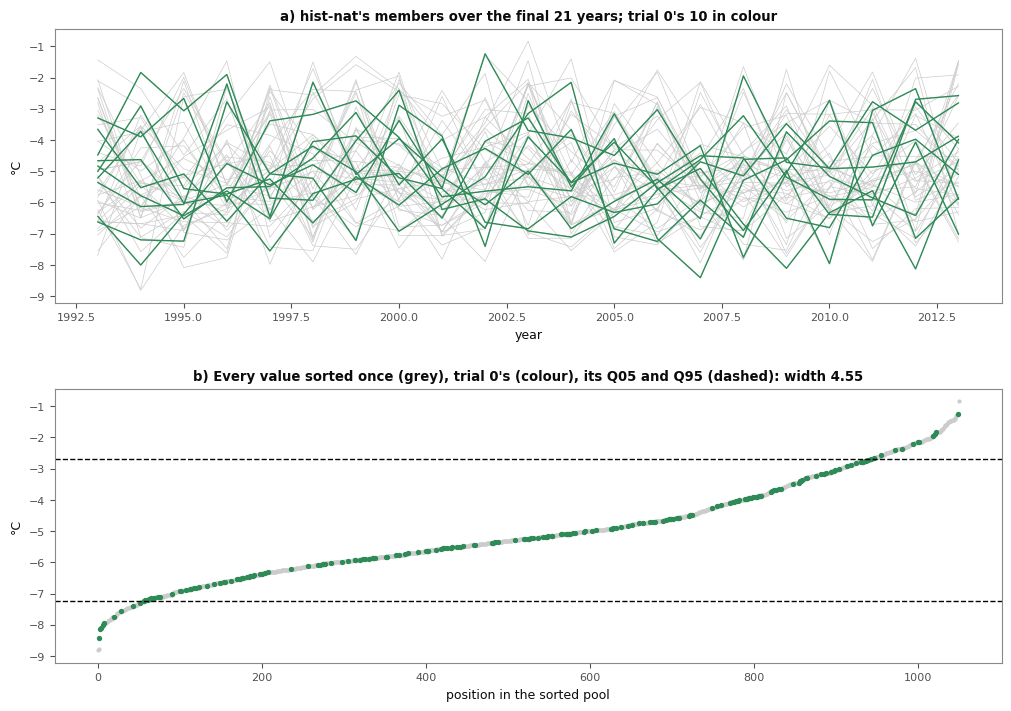

In [98]:
#(t): The sorted pool step by step, trial 0: a) hist-nat's members over the final years, trial 0's in colour; b) every
#(t): value sorted once (grey), trial 0's in colour, and its Q05 and Q95 (dashed), where the two walks stop
demo_pool_positions_arr = np.arange(demo_sorted_values_arr.size)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), layout='constrained')
demo_histnat_final_da.plot.line(ax=ax1, x='year', hue='member', add_legend=False, color='0.8', lw=0.5)
demo_histnat_final_da.isel(member=demo_trial_0_members_arr).plot.line(ax=ax1, x='year', hue='member', add_legend=False,
                                                                      color=FORCING_COLORS['hist-nat'], lw=1)
ax1.set(title=f"a) hist-nat's members over the final {WINDOW} years; trial 0's {demo_trial_0_members_arr.size} in colour",
        ylabel=VARIABLE.units)
ax2.scatter(demo_pool_positions_arr[~demo_in_trial_arr], demo_sorted_values_arr[~demo_in_trial_arr], s=4, color='0.8')
ax2.scatter(demo_pool_positions_arr[demo_in_trial_arr], demo_sorted_values_arr[demo_in_trial_arr], s=8,
            color=FORCING_COLORS['hist-nat'])
ax2.axhline(demo_trial_q05, color='k', ls='--', lw=1)
ax2.axhline(demo_trial_q95, color='k', ls='--', lw=1)
ax2.set(title=f"b) Every value sorted once (grey), trial 0's (colour), its Q05 and Q95 (dashed): width "
              f"{demo_trial_q95 - demo_trial_q05:.2f}", xlabel='position in the sorted pool', ylabel=VARIABLE.units);

In [99]:
#(t): The p-value: where the experiment's width falls among the trials'
demo_qrange_pvalue_da = sig.pvalue_two_sided(demo_trial_qrange_da, demo_experiment_qrange_da)
demo_qrange_pvalue_da

<xarray.DataArray 'tas' ()> Size: 8B
0.0118
Coordinates:
    lat      float64 8B -75.0
    lon      float64 8B -180.0
    season   <U3 12B 'DJF'

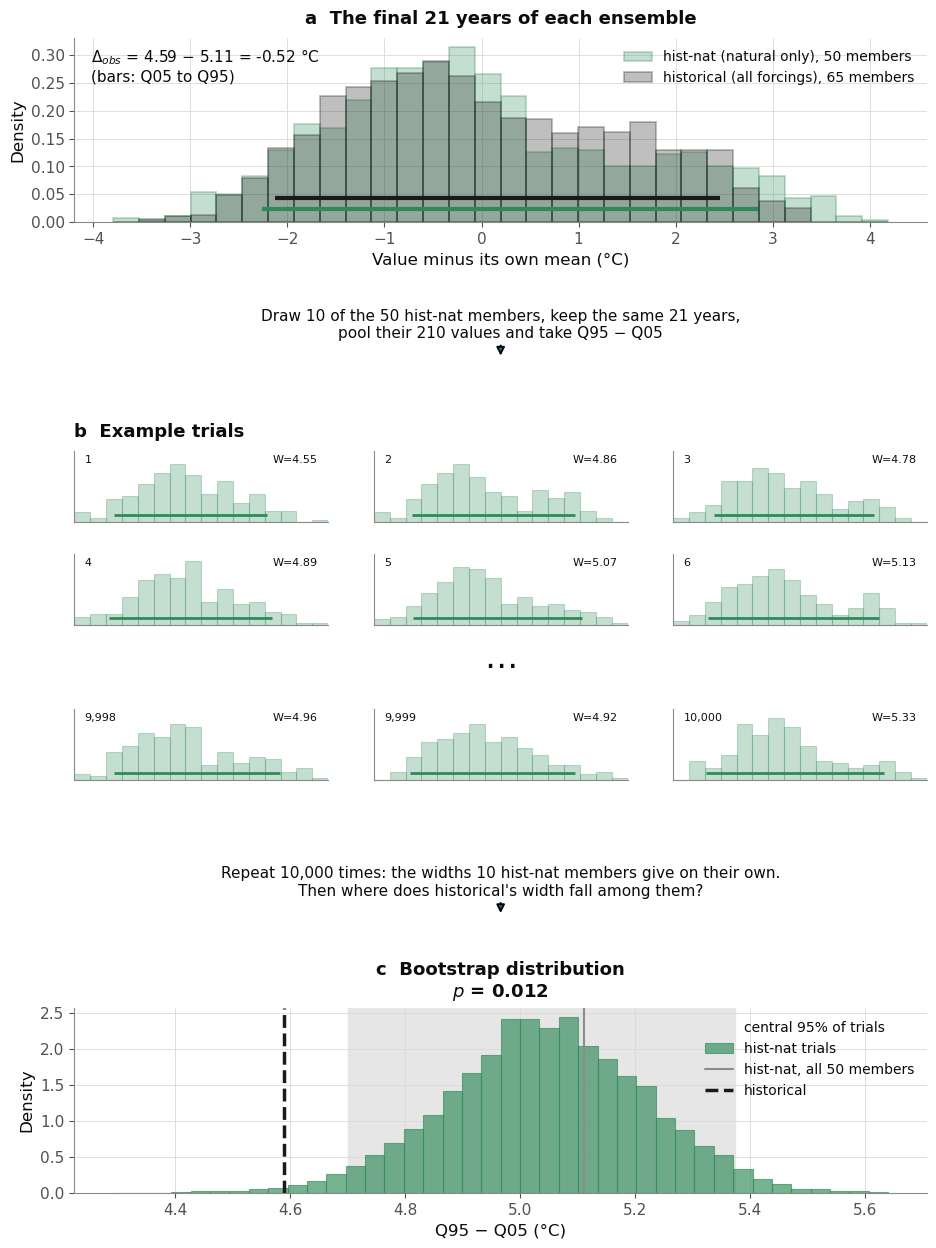

In [100]:
#(t): The hist-nat bootstrap of the width, step by step: a) the two ensembles over the same final years, centred, with
#(t): their Q05-Q95; b) example trials, each N hist-nat members over those years; c) every trial's width, and the
#(t): experiment's. The trials in b are rebuilt from demo_selected_arr and checked against demo_trial_qrange_da
n_histnat_members = demo_histnat_final_da.sizes['member']
n_drawn = int(demo_selected_arr[0].sum())
n_final_years = demo_histnat_final_da.sizes['year']
n_trials = demo_trial_qrange_da.sizes['trial']
#(c): In the slides' big text, as the schematics are shown in talks too
with plt.rc_context(fr.SLIDES.rc):
    fig = plt.figure(figsize=(11, 15))
    ax_a, flow_axes, trial_axes, ax_c = methods.schematic_axes(fig)

    methods.plot_centred_ensembles(demo_histnat_final_da, demo_experiment_final_da, DEMO_EXPERIMENT,
                                   demo_experiment_qrange_da, quantiles=QRANGE_QUANTILES, units=VARIABLE.units, ax=ax_a)
    ax_a.set_title(f'a  The final {n_final_years} years of each ensemble', pad=10)
    ax_a.set_xlabel(f'Value minus its own mean ({VARIABLE.units})')
    ax_a.set_ylabel('Density')

    methods.plot_flow(f'Draw {n_drawn} of the {n_histnat_members} hist-nat members, keep the same {n_final_years} years,\n'
                      f'pool their {n_drawn * n_final_years} values and take Q95 − Q05', flow_axes[0])
    methods.plot_width_trials(demo_histnat_final_da, demo_selected_arr, demo_trial_qrange_da, trial_axes,
                              quantiles=QRANGE_QUANTILES)
    trial_axes[0, 0].set_title('b  Example trials', loc='left', pad=10)
    methods.plot_flow(f'Repeat {n_trials:,} times: the widths {n_drawn} hist-nat members give on their own.\n'
                      f"Then where does {DEMO_EXPERIMENT}'s width fall among them?", flow_axes[1])

    methods.plot_trial_distribution(demo_trial_qrange_da, demo_experiment_qrange_da, demo_hist_nat_qrange_da,
                                    DEMO_EXPERIMENT, n_histnat_members, ax=ax_c)
    ax_c.set_title(f'c  Bootstrap distribution\n$p$ = {float(demo_qrange_pvalue_da):.3f}', pad=8)
    ax_c.set_xlabel(f'Q95 − Q05 ({VARIABLE.units})')
    ax_c.set_ylabel('Density');

In [101]:
#(t): The same change through time: DEMO_EXPERIMENT's rolling width, from its rolling quantiles
demo_rolling_qrange_da = demo_rolling_da.sel(quantile=Q_HIGH) - demo_rolling_da.sel(quantile=Q_LOW)

In [102]:
#(t): minus hist-nat's width over the final years
demo_rolling_change_da = demo_rolling_qrange_da - demo_hist_nat_qrange_da
demo_rolling_change_da

<xarray.DataArray 'tas' (year: 164)> Size: 1kB
nan nan nan nan nan nan nan nan nan nan ... nan nan nan nan nan nan nan nan nan
Coordinates:
  * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'

In [103]:
#(t): The trials as changes: each trial's width minus hist-nat's
demo_null_da = demo_trial_qrange_da - demo_hist_nat_qrange_da

In [104]:
#(t): Their central 95% and median
demo_null_bounds_da = demo_null_da.quantile([0.025, 0.5, 0.975], dim='trial')
demo_null_bounds_da

<xarray.DataArray 'tas' (quantile: 3)> Size: 24B
-0.4095 -0.06681 0.2624
Coordinates:
  * quantile  (quantile) float64 24B 0.025 0.5 0.975

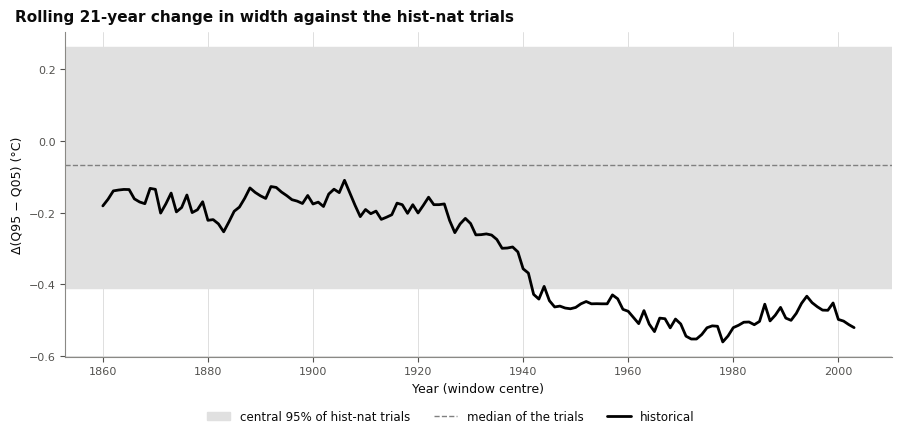

In [105]:
#(t): The rolling WINDOW-year change in width through time, against the central 95% (grey) and median (dashed) of the
#(t): hist-nat trials
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=1, n_cols=1, n_legends=1, panel_width=8.0, panel_height=2.6),
                 layout='constrained')
axes = fig.add_gridspec(1, 1).subplots(squeeze=False)
axes[0, 0].axhspan(float(demo_null_bounds_da[0]), float(demo_null_bounds_da[2]), color='0.88')
axes[0, 0].axhline(float(demo_null_bounds_da[1]), color='0.5', ls='--', lw=1)
charts.plot_lines(demo_rolling_change_da, 'year', ax=axes[0, 0], color='k', linewidth=2)
axes[0, 0].set_xlabel('Year (window centre)')
axes[0, 0].set_ylabel(f'Δ(Q95 − Q05) ({VARIABLE.units})')
fig.legend(handles=[Patch(color='0.88', label='central 95% of hist-nat trials'),
                    Line2D([], [], color='0.5', ls='--', lw=1, label='median of the trials'),
                    Line2D([], [], color='k', lw=2, label=DEMO_EXPERIMENT)],
           loc='outside lower center', ncols=3, frameon=False)
fig.suptitle(f'Rolling {WINDOW}-year change in width against the hist-nat trials', x=0.01, ha='left');

**The width of the internal variability.** Pooling 21 years of raw values into one width includes any forced change *within* those years: a warming trend slightly widens the pooled distribution. So each member first has its own experiment's forced response removed: the ensemble median in each year, smoothed with LOWESS (81 years),

$$
x'_{m,y} = x_{m,y} - \mathrm{LOWESS}\left(\operatorname{median}_m x_{m,y}\right),
$$

and the tests compare the width of the internal variability alone. The smoothing matters: subtracting the raw ensemble median would also strip its sampling noise from every member and shrink the spread, most for the smallest ensembles. To test the raw values instead, make `qrange_tree` from `lesfmip_season_tree` itself.

In [106]:
#(t): DEMO_EXPERIMENT's forced response at the point, on (year)
demo_forced_da = rc.forced_response(demo_experiment_da)

In [107]:
#(t): Each member minus it: the internal variability, on (member, year)
demo_internal_da = demo_experiment_da - demo_forced_da
demo_internal_da

<xarray.DataArray 'tas' (member: 65, year: 164)> Size: 85kB
2.94 -0.2193 -0.3262 0.8061 -0.6886 0.7278 ... 1.723 -1.919 1.552 0.262 -0.2261
Coordinates:
  * member   (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
  * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'

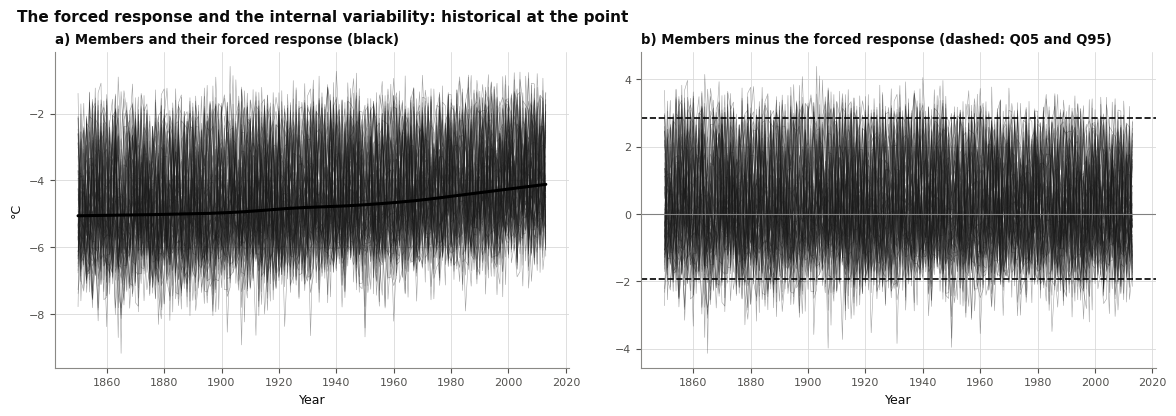

In [108]:
#(t): a) the members and their forced response (black); b) what is left once it is removed, the internal variability,
#(t): with its Q05 and Q95 (dashed)
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=1, n_cols=2, n_legends=0, panel_width=5.0, panel_height=2.8,
                                                  column_gap=0.75), layout='constrained')
axes = fig.add_gridspec(1, 2).subplots(squeeze=False)
charts.plot_lines(demo_experiment_da, 'year', ax=axes[0, 0], color=FORCING_COLORS[DEMO_EXPERIMENT], linewidth=0.4,
                  alpha=0.4)
charts.plot_lines(demo_forced_da, 'year', ax=axes[0, 0], color='k', linewidth=2.2)
charts.plot_lines(demo_internal_da, 'year', ax=axes[0, 1], color=FORCING_COLORS[DEMO_EXPERIMENT], linewidth=0.4,
                  alpha=0.4)
for quantile in QRANGE_QUANTILES:
    axes[0, 1].axhline(float(demo_internal_da.quantile(quantile)), color='k', lw=1.2, ls='--')
axes[0, 1].axhline(0, color='0.5', lw=0.8)
axes[0, 0].set_title('a) Members and their forced response (black)', loc='left')
axes[0, 0].set_ylabel(VARIABLE.units)
axes[0, 1].set_title(f'b) Members minus the forced response (dashed: Q{QRANGE_QUANTILES[0] * 100:02.0f} and '
                     f'Q{QRANGE_QUANTILES[1] * 100:02.0f})', loc='left')
for ax in axes[0]:
    ax.set_xlabel('Year')
fig.suptitle(f'The forced response and the internal variability: {DEMO_EXPERIMENT} at the point', x=0.01, ha='left');

In [109]:
#(t): The forced response of every model and experiment, on (year, season, lat, lon)
# (c): THis is needed, as the forced response must be remvoed to analyse the variance change,
# particulary if looking over longer periods like 21 years. 
forced_tree = lesfmip_season_tree.map_over_datasets(rc.forced_response)

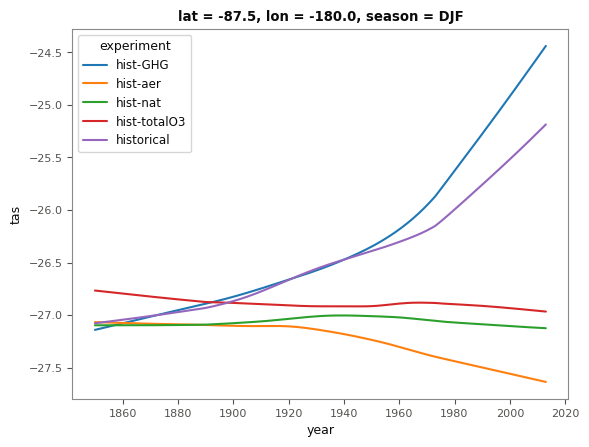

In [110]:
datatree.tree_to_dataset(forced_tree['CanESM5'], dims=['experiment']).tas.isel(lat=0, lon=0, season=0).plot(hue='experiment')

In [111]:
#(t): Every member minus its experiment's forced response: what the width test, the tails and the zonal test use
qrange_tree = lesfmip_season_tree - forced_tree

In [112]:
qrange_tree

<xarray.DataTree>
Group: /
├── Group: /GISS-E2-1-G
│   ├── Group: /GISS-E2-1-G/historical
│   │       Dimensions:  (lon: 144, year: 164, season: 4, lat: 20, member: 63)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * member   (member) object 504B 'r10i1p1f1' 'r10i1p1f2' ... 'r9i1p5f1'
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season) float64 952MB dask.array<chunksize=(63, 4, 144, 164, 4), meta=np.ndarray>
│   ├── Group: /GISS-E2-1-G/hist-GHG
│   │       Dimensions:  (lon: 144, member: 45, season: 4, lat: 20, year: 164)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * member   (member) object 360B 'r10i1p1f2' 'r10i1p3f1' ... 'r9i1p3f1'
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season) float64 680MB dask.array<chunksize=(45, 4, 144, 164, 4), meta=np.ndarray>
│   ├── Group: /GISS-E2-1-G/hist-nat
│   │       Dimensions:  (member: 20, lon: 144, lat: 20, year: 164, season: 4)
│   │       Coordinates:
│   │         * member   (member) object 160B 'r10i1p1f3' 'r1i1p1f2' ... 'r9i1p1f3'
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season) float64 302MB dask.array<chunksize=(20, 4, 144, 164, 4), meta=np.ndarray>
│   ├── Group: /GISS-E2-1-G/hist-aer
│   │       Dimensions:  (member: 45, lon: 144, year: 164, lat: 20, season: 4)
│   │       Coordinates:
│   │         * member   (member) object 360B 'r10i1p1f2' 'r10i1p3f1' ... 'r9i1p3f1'
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season) float64 680MB dask.array<chunksize=(45, 4, 144, 164, 4), meta=np.ndarray>
│   └── Group: /GISS-E2-1-G/hist-totalO3
│           Dimensions:  (lon: 144, member: 40, year: 164, season: 4, lat: 20)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * member   (member) object 320B 'r10i1p1f2' 'r10i1p3f1' ... 'r9i1p3f1'
│             * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│           Data variables:
│               tas      (member, lat, lon, year, season) float64 605MB dask.array<chunksize=(40, 4, 144, 164, 4), meta=np.ndarray>
├── Group: /CanESM5
│   ├── Group: /CanESM5/hist-nat
│   │       Dimensions:  (member: 50, lat: 20, lon: 144, season: 4, year: 164)
│   │       Coordinates:
│   │         * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │         * lat      (lat) float64 160B -87.5 -85.0 -

In [113]:
#(c): Persisted once: the width test, the tails and the zonal test all use it, and each would redo the smoothing
qrange_tree = qrange_tree.persist()
wait(qrange_tree);

Now at every grid point. Every change is measured from hist-nat over the same final years, and the bootstrap draws from hist-nat alone, so it is drawn once per model (one function mapped over the hist-nat nodes) and every experiment of that model is tested against the same trials.

In [114]:
sig.N_BOOTSTRAP_MEMBERS

10

In [115]:
#(t): The final WINDOW years of every experiment of qrange_tree
qrange_final_tree = qrange_tree.isel(year=slice(-WINDOW, None))

In [116]:
#(t): hist-nat's alone: what every change is measured from, and all the bootstrap draws from
qrange_hist_nat_final_tree = qrange_final_tree.match('*/hist-nat')

In [ ]:
%%time
#(t): Q05, Q50 and Q95 of every experiment over its final years, members and years pooled (Q50 is for the tails,
#(t): section 4)
qrange_final_q_ds = datatree.reduce_to_dataset(qrange_final_tree,
                                               partial(qc.pooled_quantiles, quantiles=TAIL_QUANTILES)).compute()

In [118]:
#(t): hist-nat's
qrange_hist_nat_q_da = qrange_final_q_ds[VARIABLE.name].sel(experiment='hist-nat', drop=True)

In [119]:
#(t): every other experiment's
qrange_final_q_da = qrange_final_q_ds[VARIABLE.name].drop_sel(experiment='hist-nat')

In [120]:
#(t): hist-nat's width over the final years, Q95 - Q05
hist_nat_qrange_da = qrange_hist_nat_q_da.sel(quantile=Q_HIGH, drop=True) - qrange_hist_nat_q_da.sel(quantile=Q_LOW, drop=True)

In [121]:
#(t): Every experiment's width over the same years
experiment_qrange_da = qrange_final_q_da.sel(quantile=Q_HIGH, drop=True) - qrange_final_q_da.sel(quantile=Q_LOW, drop=True)

In [122]:
#(t): The change in width: the experiment's minus hist-nat's, over the same years
qrange_change_da = experiment_qrange_da - hist_nat_qrange_da

In [123]:
%%time
#(t): The bootstrap, from hist-nat alone: each trial's width, N_BOOTSTRAP_MEMBERS different members over the final
#(t): WINDOW years (numba, on the cluster)
qrange_trial_ds = datatree.reduce_to_dataset(
    qrange_hist_nat_final_tree,
    partial(sig.bootstrap_qrange, quantiles=QRANGE_QUANTILES, n_trials=N_TRIALS, seed=0),
)
qrange_trial_da = qrange_trial_ds[VARIABLE.name].sel(experiment='hist-nat', drop=True).persist()
wait(qrange_trial_da)

CPU times: user 59.9 ms, sys: 3.67 ms, total: 63.6 ms
Wall time: 8.73 s


DoneAndNotDoneFutures(done={<Future: finished, type: numpy.ndarray, key: ('getitem-4d91afd3999b09f48d869a17e93dae54', 0, 2, 0, 0, 0)>, <Future: finished, type: numpy.ndarray, key: ('getitem-4d91afd3999b09f48d869a17e93dae54', 0, 3, 0, 0, 3)>, <Future: finished, type: numpy.ndarray, key: ('getitem-4d91afd3999b09f48d869a17e93dae54', 0, 0, 0, 0, 5)>, <Future: finished, type: numpy.ndarray, key: ('getitem-4d91afd3999b09f48d869a17e93dae54', 0, 1, 0, 0, 4)>, <Future: finished, type: numpy.ndarray, key: ('getitem-4d91afd3999b09f48d869a17e93dae54', 0, 4, 0, 0, 3)>, <Future: finished, type: numpy.ndarray, key: ('getitem-4d91afd3999b09f48d869a17e93dae54', 0, 0, 0, 0, 1)>, <Future: finished, type: numpy.ndarray, key: ('getitem-4d91afd3999b09f48d869a17e93dae54', 0, 1, 0, 0, 3)>, <Future: finished, type: numpy.ndarray, key: ('getitem-4d91afd3999b09f48d869a17e93dae54', 0, 2, 0, 0, 1)>, <Future: finished, type: numpy.ndarray, key: ('getitem-4d91afd3999b09f48d869a17e93dae54', 0, 3, 0, 0, 4)>, <Future: 

In [124]:
%%time
#(t): The two-sided p-value: where every experiment's width falls among its model's trials
qrange_pvalue_da = sig.pvalue_two_sided(qrange_trial_da, experiment_qrange_da).compute()

CPU times: user 31.6 ms, sys: 5.22 ms, total: 36.8 ms
Wall time: 659 ms


In [ ]:
#(t): The trials as changes: each trial's width minus hist-nat's (for the bounds, and the zonal test of section 5)
qrange_null_da = qrange_trial_da - hist_nat_qrange_da

In [126]:
%%time
#(t): Their central 1 - ALPHA: a change outside it is significant
null_bounds_da = nan_quantile(qrange_null_da, [ALPHA / 2, 1 - ALPHA / 2], 'trial').compute()

CPU times: user 11.4 ms, sys: 0 ns, total: 11.4 ms
Wall time: 428 ms


In [127]:
#(t): The width test in one Dataset, laid out as notebook plot_03 opens it
qrange_change_ds = xr.Dataset({
    'hist_nat_qrange': hist_nat_qrange_da,
    'experiment_qrange': experiment_qrange_da,
    'qrange_change': qrange_change_da,
    'null_lower': null_bounds_da.isel(quantile=0, drop=True),
    'null_upper': null_bounds_da.isel(quantile=1, drop=True),
    'qrange_pvalue': qrange_pvalue_da,
    'qrange_significant': qrange_pvalue_da < ALPHA,
})
qrange_change_ds

<xarray.Dataset> Size: 9MB
Dimensions:             (model: 6, lon: 144, season: 4, lat: 20, experiment: 4)
Coordinates:
  * model               (model) object 48B 'CanESM5' ... 'NorESM2-LM'
  * lon                 (lon) float64 1kB -180.0 -177.5 -175.0 ... 175.0 177.5
  * season              (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat                 (lat) float64 160B -87.5 -85.0 -82.5 ... -42.5 -40.0
  * experiment          (experiment) object 32B 'hist-GHG' ... 'historical'
Data variables:
    hist_nat_qrange     (lat, lon, season, model) float64 553kB 2.829 ... 1.51
    experiment_qrange   (lat, lon, season, model, experiment) float64 2MB 2.8...
    qrange_change       (lat, lon, season, model, experiment) float64 2MB 0.0...
    null_lower          (lat, lon, season, model) float64 553kB -0.3474 ... -...
    null_upper          (lat, lon, season, model) float64 553kB 0.2492 ... 0....
    qrange_pvalue       (lat, lon, season, model, experiment) float64 2MB 0.6...
    qrange_significant  (lat, lon, season, model, experiment) bool 276kB Fals...

In [128]:
#(t): Saved for notebooks plot_03 to plot_06
qrange_change_path = RESULTS_DIR / 'qrange_change.zarr'
qrange_change_ds.to_zarr(qrange_change_path, mode='w')
qrange_change_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/qrange_change.zarr')

In [129]:
#(t): The quantiles the width test is made from, laid out as notebook plot_03 opens them: hist-nat's and every
#(t): experiment's over the final WINDOW years (both of qrange_tree)
width_quantiles_ds = xr.Dataset({'hist_nat': qrange_hist_nat_q_da, 'final': qrange_final_q_da})
width_quantiles_ds

<xarray.Dataset> Size: 8MB
Dimensions:     (model: 6, lon: 144, season: 4, lat: 20, quantile: 3,
                 experiment: 4)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * quantile    (quantile) float64 24B 0.05 0.5 0.95
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'
Data variables:
    hist_nat    (lat, lon, season, quantile, model) float64 2MB -1.375 ... 0....
    final       (lat, lon, season, quantile, model, experiment) float64 7MB -...

In [130]:
#(t): Saved for notebooks plot_03 to plot_06
width_quantiles_path = RESULTS_DIR / 'width_quantiles.zarr'
width_quantiles_ds.to_zarr(width_quantiles_path, mode='w')
width_quantiles_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/width_quantiles.zarr')

In [131]:
#(t): The result at the demonstration point (of qrange_tree, so with the forced response removed)
qrange_change_ds.sel(**DEMO_SEL, experiment=DEMO_EXPERIMENT).sel(**DEMO_LATLON)

<xarray.Dataset> Size: 145B
Dimensions:             ()
Coordinates:
    model               <U7 28B 'CanESM5'
    lon                 float64 8B -180.0
    season              <U3 12B 'DJF'
    lat                 float64 8B -75.0
    experiment          <U10 40B 'historical'
Data variables:
    hist_nat_qrange     float64 8B 5.11
    experiment_qrange   float64 8B 4.559
    qrange_change       float64 8B -0.551
    null_lower          float64 8B -0.3988
    null_upper          float64 8B 0.2531
    qrange_pvalue       float64 8B 0.007992
    qrange_significant  bool 1B True

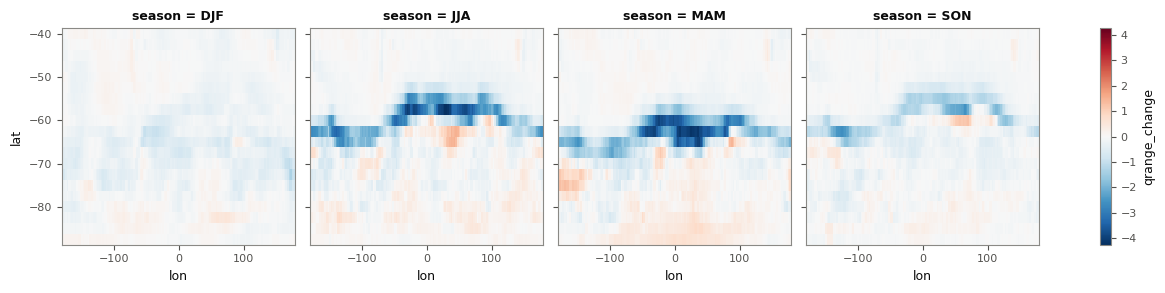

In [132]:
#(t): Quick look: the change in width for DEMO_MODEL and DEMO_EXPERIMENT, every season, on the plain lat-lon grid
qrange_change_ds['qrange_change'].sel(model=DEMO_MODEL, experiment=DEMO_EXPERIMENT).plot(
    x='lon', y='lat', col='season', cmap='RdBu_r', center=0);

### By SAM phase

The same test in the seasons of each SAM phase alone (*SAM Phases*, above): each experiment's width in a phase against hist-nat's in the same phase, and against trials of the same 10 hist-nat members, each pooling only its seasons in that phase (about 70 of its 210). Fewer seasons make every width noisier, so less comes out significant than over all seasons.

In [133]:
#(t): The internal variability over the final WINDOW years (qrange_final_tree), of the nodes with an index
qrange_sam_final_tree = qrange_final_tree.filter(lambda node: node.relative_to(qrange_final_tree) in sam_both_paths)

In [134]:
#(t): Split into the three phases: NaN outside each phase's seasons, on (phase, member, year, season, lat, lon)
qrange_phase_tree = xr.map_over_datasets(sam.by_phase, qrange_sam_final_tree, sam_final_masks_tree)

In [ ]:
%%time
#(t): Q05, Q50 and Q95 in each phase, members and years pooled, every experiment (Q50 is for the tails, section 4)
phase_qrange_q_ds = datatree.reduce_to_dataset(qrange_phase_tree,
                                               partial(qc.pooled_quantiles, quantiles=TAIL_QUANTILES)).compute()

In [136]:
#(t): hist-nat's
phase_hist_nat_q_da = phase_qrange_q_ds[VARIABLE.name].sel(experiment='hist-nat', drop=True)

In [137]:
#(t): every other experiment's
phase_final_q_da = phase_qrange_q_ds[VARIABLE.name].drop_sel(experiment='hist-nat')

In [138]:
#(t): hist-nat's width in each phase, Q95 - Q05
phase_hist_nat_qrange_da = phase_hist_nat_q_da.sel(quantile=Q_HIGH, drop=True) - phase_hist_nat_q_da.sel(quantile=Q_LOW, drop=True)

In [139]:
#(t): every experiment's
phase_experiment_qrange_da = phase_final_q_da.sel(quantile=Q_HIGH, drop=True) - phase_final_q_da.sel(quantile=Q_LOW, drop=True)

In [140]:
#(t): The change in width in each phase
phase_qrange_change_da = phase_experiment_qrange_da - phase_hist_nat_qrange_da

In [141]:
%%time
#(t): The bootstrap in each phase: the same draws (the same seed), each trial pooling its members' seasons in the phase
phase_qrange_trial_ds = datatree.reduce_to_dataset(
    qrange_phase_tree.match('*/hist-nat'),
    partial(sig.bootstrap_qrange, quantiles=QRANGE_QUANTILES, n_trials=N_TRIALS, seed=0),
)
phase_qrange_trial_da = phase_qrange_trial_ds[VARIABLE.name].sel(experiment='hist-nat', drop=True).persist()
wait(phase_qrange_trial_da)

CPU times: user 63.7 ms, sys: 4.8 ms, total: 68.5 ms
Wall time: 4.96 s


DoneAndNotDoneFutures(done={<Future: finished, type: numpy.ndarray, key: ('getitem-c68400333be6268ae67fffcf58f2bad9', 0, 0, 0, 0, 0, 2)>, <Future: finished, type: numpy.ndarray, key: ('getitem-c68400333be6268ae67fffcf58f2bad9', 0, 3, 0, 0, 0, 2)>, <Future: finished, type: numpy.ndarray, key: ('getitem-c68400333be6268ae67fffcf58f2bad9', 0, 1, 0, 0, 0, 0)>, <Future: finished, type: numpy.ndarray, key: ('getitem-c68400333be6268ae67fffcf58f2bad9', 0, 0, 0, 0, 0, 1)>, <Future: finished, type: numpy.ndarray, key: ('getitem-c68400333be6268ae67fffcf58f2bad9', 0, 4, 0, 0, 0, 4)>, <Future: finished, type: numpy.ndarray, key: ('getitem-c68400333be6268ae67fffcf58f2bad9', 0, 2, 0, 0, 0, 4)>, <Future: finished, type: numpy.ndarray, key: ('getitem-c68400333be6268ae67fffcf58f2bad9', 0, 3, 0, 0, 0, 1)>, <Future: finished, type: numpy.ndarray, key: ('getitem-c68400333be6268ae67fffcf58f2bad9', 0, 1, 0, 0, 0, 4)>, <Future: finished, type: numpy.ndarray, key: ('getitem-c68400333be6268ae67fffcf58f2bad9', 0,

In [142]:
%%time
#(t): The p-value of every experiment's width in each phase against its model's trials in that phase
phase_qrange_pvalue_da = sig.pvalue_two_sided(phase_qrange_trial_da, phase_experiment_qrange_da).compute()

CPU times: user 39.5 ms, sys: 19.9 ms, total: 59.4 ms
Wall time: 1.55 s


In [143]:
#(t): The trials as changes: each trial's width minus hist-nat's, in each phase
phase_qrange_null_da = phase_qrange_trial_da - phase_hist_nat_qrange_da

In [144]:
%%time
#(t): Their central 1 - ALPHA
phase_null_bounds_da = nan_quantile(phase_qrange_null_da, [ALPHA / 2, 1 - ALPHA / 2], 'trial').compute()

CPU times: user 14.4 ms, sys: 4.64 ms, total: 19.1 ms
Wall time: 495 ms


In [145]:
#(t): The width test by SAM phase in one Dataset, laid out as qrange_change_ds with a phase dim
sam_qrange_change_ds = xr.Dataset({
    'hist_nat_qrange': phase_hist_nat_qrange_da,
    'experiment_qrange': phase_experiment_qrange_da,
    'qrange_change': phase_qrange_change_da,
    'null_lower': phase_null_bounds_da.isel(quantile=0, drop=True),
    'null_upper': phase_null_bounds_da.isel(quantile=1, drop=True),
    'qrange_pvalue': phase_qrange_pvalue_da,
    'qrange_significant': phase_qrange_pvalue_da < ALPHA,
})
sam_qrange_change_ds

<xarray.Dataset> Size: 26MB
Dimensions:             (model: 6, lon: 144, season: 4, lat: 20, phase: 3,
                         experiment: 4)
Coordinates:
  * model               (model) object 48B 'CanESM5' ... 'NorESM2-LM'
  * lon                 (lon) float64 1kB -180.0 -177.5 -175.0 ... 175.0 177.5
  * season              (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat                 (lat) float64 160B -87.5 -85.0 -82.5 ... -42.5 -40.0
  * phase               (phase) <U8 96B 'negative' 'neutral' 'positive'
  * experiment          (experiment) object 32B 'hist-GHG' ... 'historical'
Data variables:
    hist_nat_qrange     (lat, lon, season, phase, model) float64 2MB 2.732 .....
    experiment_qrange   (lat, lon, season, phase, model, experiment) float64 7MB ...
    qrange_change       (lat, lon, season, phase, model, experiment) float64 7MB ...
    null_lower          (lat, lon, season, phase, model) float64 2MB -0.6219 ...
    null_upper          (lat, lon, season, phase, model) float64 2MB 0.35 ......
    qrange_pvalue       (lat, lon, season, phase, model, experiment) float64 7MB ...
    qrange_significant  (lat, lon, season, phase, model, experiment) bool 829kB ...

In [146]:
#(t): Saved for notebooks plot_03 to plot_06
sam_qrange_change_path = RESULTS_DIR / 'sam_qrange_change.zarr'
sam_qrange_change_ds.to_zarr(sam_qrange_change_path, mode='w')
sam_qrange_change_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/sam_qrange_change.zarr')

In [147]:
#(t): The quantiles it is made from, laid out as width_quantiles_ds with a phase dim
sam_width_quantiles_ds = xr.Dataset({'hist_nat': phase_hist_nat_q_da, 'final': phase_final_q_da})
sam_width_quantiles_ds

<xarray.Dataset> Size: 25MB
Dimensions:     (model: 6, lon: 144, season: 4, lat: 20, phase: 3, quantile: 3,
                 experiment: 4)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * phase       (phase) <U8 96B 'negative' 'neutral' 'positive'
  * quantile    (quantile) float64 24B 0.05 0.5 0.95
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'
Data variables:
    hist_nat    (lat, lon, season, phase, quantile, model) float64 5MB -0.990...
    final       (lat, lon, season, phase, quantile, model, experiment) float64 20MB ...

In [148]:
#(t): Saved for notebooks plot_03 to plot_06
sam_width_quantiles_path = RESULTS_DIR / 'sam_width_quantiles.zarr'
sam_width_quantiles_ds.to_zarr(sam_width_quantiles_path, mode='w')
sam_width_quantiles_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/sam_width_quantiles.zarr')

In [149]:
#(t): The result at the demonstration point, every phase
sam_qrange_change_ds.sel(**DEMO_SEL, experiment=DEMO_EXPERIMENT).sel(**DEMO_LATLON).to_dataframe().round(3)

,model,lon,season,lat,hist_nat_qrange,experiment,experiment_qrange,qrange_change,null_lower,null_upper,qrange_pvalue,qrange_significant
phase,,,,,,,,,,,,
negative,CanESM5,-180.0,DJF,-75.0,5.056,historical,4.093,-0.963,-0.809,0.496,0.024,True
neutral,CanESM5,-180.0,DJF,-75.0,5.007,historical,4.623,-0.385,-0.736,0.280,0.418,False
positive,CanESM5,-180.0,DJF,-75.0,5.228,historical,4.537,-0.691,-0.671,0.441,0.048,True


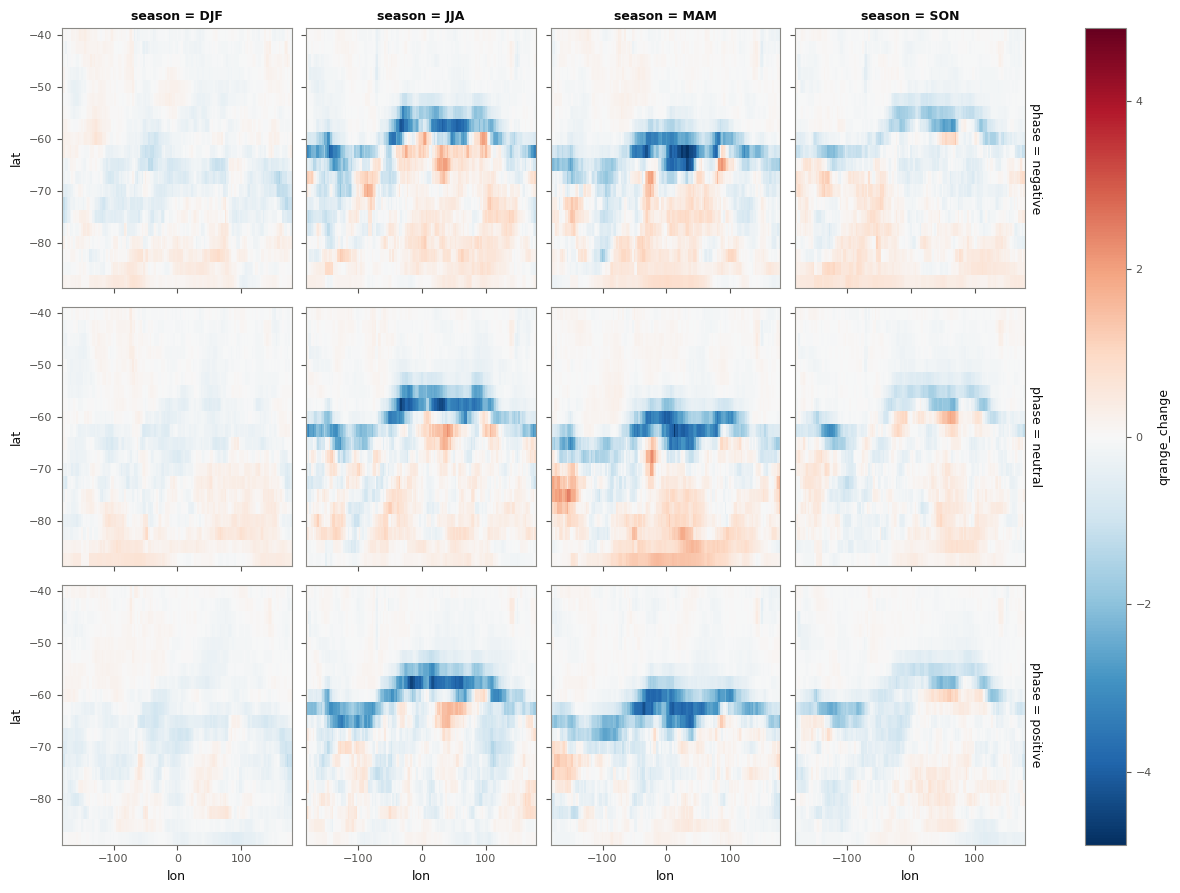

In [150]:
#(t): Quick look: DEMO_MODEL's change in width in each phase, DEMO_EXPERIMENT
sam_qrange_change_ds['qrange_change'].sel(model=DEMO_MODEL, experiment=DEMO_EXPERIMENT).plot(
    x='lon', y='lat', row='phase', col='season', cmap='RdBu_r', center=0);

## 3. Quantile Response

The change in every 5th percentile, the final $L$ years of each experiment against hist-nat's over the same years (members and years pooled), as for the mean and the width:

$$
\Delta Q_p = Q_p\left(x^{\mathrm{exp}}_{\text{final } L \text{ years}}\right) - Q_p\left(x^{\mathrm{nat}}_{\text{final } L \text{ years}}\right), \qquad p = 0.05,\ 0.10,\ \ldots,\ 0.95.
$$

The maps keep $p = 0.05,\ 0.5,\ 0.95$; the curve is every $p$ as an Antarctic (area-weighted) mean. A flat curve of $\Delta Q_p$ against $p$ is a pure shift of the distribution; a rising curve means the warm tail moves more than the cold one.

In [151]:
#(t): The quantile levels: every 5th percentile, Q05 to Q95
curve_quantiles_arr = np.round(np.arange(0.05, 1.00, 0.05), 2)

In [152]:
#(t): The final WINDOW years of every experiment (the seasonal means themselves, not qrange_tree)
lesfmip_final_tree = lesfmip_season_tree.isel(year=slice(-WINDOW, None))

In [153]:
%%time
#(t): Every experiment's quantiles over its final years, members and years pooled (hist-nat's too)
final_q_ds = datatree.reduce_to_dataset(lesfmip_final_tree,
                                        partial(qc.pooled_quantiles, quantiles=curve_quantiles_arr)).compute()
final_q_da = final_q_ds[VARIABLE.name].drop_sel(experiment='hist-nat')
final_q_da

CPU times: user 180 ms, sys: 66.3 ms, total: 247 ms
Wall time: 796 ms


<xarray.DataArray 'tas' (lat: 20, lon: 144, season: 4, quantile: 19, model: 6,
                         experiment: 4)> Size: 42MB
-26.2 -28.94 -28.34 -26.92 -30.93 -33.21 ... 12.41 13.08 15.06 14.51 14.4 14.93
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * quantile    (quantile) float64 152B 0.05 0.1 0.15 0.2 ... 0.8 0.85 0.9 0.95

In [154]:
#(t): hist-nat's quantiles over the same years
hist_nat_q_da = final_q_ds[VARIABLE.name].sel(experiment='hist-nat', drop=True)
hist_nat_q_da

<xarray.DataArray 'tas' (lat: 20, lon: 144, season: 4, quantile: 19, model: 6)> Size: 11MB
-28.49 -32.84 -30.05 -20.71 -30.58 -30.87 ... 12.92 13.49 14.98 12.22 14.62
Coordinates:
  * model     (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * lon       (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * season    (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat       (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * quantile  (quantile) float64 152B 0.05 0.1 0.15 0.2 ... 0.8 0.85 0.9 0.95

In [155]:
#(t): The change in every quantile: final years minus hist-nat's over the same years
quantile_change_da = final_q_da - hist_nat_q_da

In [156]:
#(t): The maps: Q05, Q50 and Q95
quantile_response_da = quantile_change_da.sel(quantile=[0.05, 0.50, 0.95])
quantile_response_da = quantile_response_da.rename('quantile_response')
quantile_response_da

<xarray.DataArray 'quantile_response' (lat: 20, lon: 144, season: 4,
                                       quantile: 3, model: 6, experiment: 4)> Size: 7MB
2.291 -0.4499 0.1507 1.576 1.903 -0.3701 ... 0.8635 0.4323 -0.1161 -0.2198 0.307
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * quantile    (quantile) float64 24B 0.05 0.5 0.95

In [157]:
#(t): The curve: every quantile's change as an Antarctic (area-weighted) mean
quantile_curve_da = sig.area_mean(quantile_change_da)
quantile_curve_da = quantile_curve_da.rename('quantile_curve')
quantile_curve_da

<xarray.DataArray 'quantile_curve' (season: 4, quantile: 19, model: 6,
                                    experiment: 4)> Size: 15kB
1.201 -0.3003 0.2516 0.9591 0.7101 ... 0.6549 0.3432 -0.2387 -0.06973 0.2687
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * quantile    (quantile) float64 152B 0.05 0.1 0.15 0.2 ... 0.8 0.85 0.9 0.95

In [158]:
#(t): Saved for notebooks plot_03 to plot_06
quantile_response_path = RESULTS_DIR / 'quantile_response.zarr'
quantile_response_da.to_dataset(name='quantile_response').to_zarr(quantile_response_path, mode='w')
quantile_response_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/quantile_response.zarr')

In [159]:
#(t): Saved for notebooks plot_03 to plot_06
quantile_curve_path = RESULTS_DIR / 'quantile_curve.zarr'
quantile_curve_da.to_dataset(name='quantile_curve').to_zarr(quantile_curve_path, mode='w')
quantile_curve_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/quantile_curve.zarr')

In [160]:
#(t): Saved for notebooks plot_03 to plot_06
final_quantiles_path = RESULTS_DIR / 'final_quantiles.zarr'
final_q_da.to_dataset(name=VARIABLE.name).to_zarr(final_quantiles_path, mode='w')
final_quantiles_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/final_quantiles.zarr')

In [161]:
#(t): Saved for notebooks plot_03 to plot_06
hist_nat_final_quantiles_path = RESULTS_DIR / 'hist_nat_final_quantiles.zarr'
hist_nat_q_da.to_dataset(name=VARIABLE.name).to_zarr(hist_nat_final_quantiles_path, mode='w')
hist_nat_final_quantiles_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/hist_nat_final_quantiles.zarr')

In [162]:
#(t): The change in the three quantiles at the demonstration point, DEMO_MODEL
quantile_response_da.sel(**DEMO_SEL).sel(**DEMO_LATLON).to_pandas().round(2)

experiment,hist-GHG,hist-aer,hist-totalO3,historical
quantile,,,,
0.05,1.04,0.20,0.42,1.08
0.50,0.62,0.10,0.32,1.00
0.95,0.33,0.21,0.14,0.56


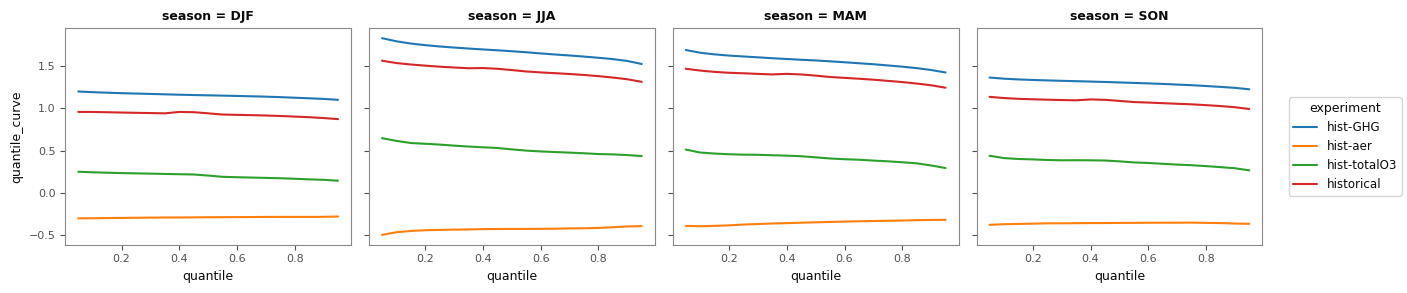

In [163]:
#(t): Quick look: DEMO_MODEL's Antarctic-mean change in every 5th percentile, one panel per season
quantile_curve_da.sel(model=DEMO_MODEL).plot.line(x='quantile', hue='experiment', col='season');

## 4. The Tails

The combined figures in notebook plot_03 put the change in width next to the change in each tail: the warm tail's length $Q_{95} - Q_{50}$ and the cold tail's $Q_{50} - Q_{05}$, each experiment's final years against hist-nat's over the same years, from the quantiles of section 2 (on `qrange_tree`), so that

$$
\Delta(Q_{95} - Q_{50}) + \Delta(Q_{50} - Q_{05}) = \Delta(Q_{95} - Q_{05}).
$$

The mean response they are drawn next to is notebook calc_02b's (section 1).

In [271]:
#(t): The change in Q05, Q50 and Q95 of qrange_tree (section 2): final years minus hist-nat's over the same years
tail_q_change_da = qrange_final_q_da - qrange_hist_nat_q_da

In [272]:
#(t): Each of the three
q05_change_da = tail_q_change_da.sel(quantile=Q_LOW, drop=True)
q50_change_da = tail_q_change_da.sel(quantile=0.50, drop=True)
q95_change_da = tail_q_change_da.sel(quantile=Q_HIGH, drop=True)

In [273]:
#(t): The change in the warm tail's length, Q95 - Q50, and in the cold tail's, Q50 - Q05
upper_tail_change_da = q95_change_da - q50_change_da
lower_tail_change_da = q50_change_da - q05_change_da

In [274]:
#(t): The tails in one Dataset, laid out as notebook plot_03 opens it: their sum is the change in width, their difference
#(t): the asymmetry (> 0 when the warm tail stretches more)
tails_ds = xr.Dataset({
    'upper_tail_change': upper_tail_change_da,
    'lower_tail_change': lower_tail_change_da,
    'width_change': upper_tail_change_da + lower_tail_change_da,
    'tail_asymmetry': upper_tail_change_da - lower_tail_change_da,
    'q05_change': q05_change_da,
    'q50_change': q50_change_da,
    'q95_change': q95_change_da,
})
tails_ds

<xarray.Dataset> Size: 15MB
Dimensions:            (model: 6, experiment: 4, lon: 144, season: 4, lat: 20)
Coordinates:
  * model              (model) object 48B 'CanESM5' ... 'NorESM2-LM'
  * experiment         (experiment) object 32B 'hist-GHG' ... 'historical'
  * lon                (lon) float64 1kB -180.0 -177.5 -175.0 ... 175.0 177.5
  * season             (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat                (lat) float64 160B -87.5 -85.0 -82.5 ... -42.5 -40.0
Data variables:
    upper_tail_change  (lat, lon, season, model, experiment) float64 2MB -0.0...
    lower_tail_change  (lat, lon, season, model, experiment) float64 2MB 0.03...
    width_change       (lat, lon, season, model, experiment) float64 2MB 0.01...
    tail_asymmetry     (lat, lon, season, model, experiment) float64 2MB -0.0...
    q05_change         (lat, lon, season, model, experiment) float64 2MB 0.00...
    q50_change         (lat, lon, season, model, experiment) float64 2MB 0.03...
    q95_change         (lat, lon, season, model, experiment) float64 2MB 0.02...

In [276]:
#(t): Saved for notebooks plot_03 to plot_06
tails_path = RESULTS_DIR / 'tails.zarr'
tails_ds.to_zarr(tails_path, mode='w')
tails_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/tails.zarr')

In [ ]:
#(t): Quick look: DEMO_MODEL's change in width in one season, from the tails
tails_ds['width_change'].sel(**DEMO_SEL).plot(x='lon', y='lat', col='experiment', cmap='RdBu_r', center=0);

### By SAM phase

The tails in each SAM phase, from the quantiles of section 2's SAM subsection (`phase_final_q_da`, `phase_hist_nat_q_da`), so they add up to its change in width in each phase.

In [278]:
#(t): The change in Q05, Q50 and Q95 in each phase: the final years minus hist-nat's in the same phase
phase_tail_q_change_da = phase_final_q_da - phase_hist_nat_q_da

In [279]:
#(t): Each of the three
phase_q05_change_da = phase_tail_q_change_da.sel(quantile=Q_LOW, drop=True)
phase_q50_change_da = phase_tail_q_change_da.sel(quantile=0.50, drop=True)
phase_q95_change_da = phase_tail_q_change_da.sel(quantile=Q_HIGH, drop=True)

In [280]:
#(t): The change in the warm tail's length, Q95 - Q50, and in the cold tail's, Q50 - Q05
phase_upper_tail_change_da = phase_q95_change_da - phase_q50_change_da
phase_lower_tail_change_da = phase_q50_change_da - phase_q05_change_da

In [281]:
#(t): The tails by SAM phase in one Dataset, laid out as tails_ds with a phase dim
sam_tails_ds = xr.Dataset({
    'upper_tail_change': phase_upper_tail_change_da,
    'lower_tail_change': phase_lower_tail_change_da,
    'width_change': phase_upper_tail_change_da + phase_lower_tail_change_da,
    'tail_asymmetry': phase_upper_tail_change_da - phase_lower_tail_change_da,
    'q05_change': phase_q05_change_da,
    'q50_change': phase_q50_change_da,
    'q95_change': phase_q95_change_da,
})
sam_tails_ds

<xarray.Dataset> Size: 46MB
Dimensions:            (model: 6, experiment: 4, lon: 144, season: 4, lat: 20,
                        phase: 3)
Coordinates:
  * model              (model) object 48B 'CanESM5' ... 'NorESM2-LM'
  * experiment         (experiment) object 32B 'hist-GHG' ... 'historical'
  * lon                (lon) float64 1kB -180.0 -177.5 -175.0 ... 175.0 177.5
  * season             (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat                (lat) float64 160B -87.5 -85.0 -82.5 ... -42.5 -40.0
  * phase              (phase) <U8 96B 'negative' 'neutral' 'positive'
Data variables:
    upper_tail_change  (lat, lon, season, phase, model, experiment) float64 7MB ...
    lower_tail_change  (lat, lon, season, phase, model, experiment) float64 7MB ...
    width_change       (lat, lon, season, phase, model, experiment) float64 7MB ...
    tail_asymmetry     (lat, lon, season, phase, model, experiment) float64 7MB ...
    q05_change         (lat, lon, season, phase, model, experiment) float64 7MB ...
    q50_change         (lat, lon, season, phase, model, experiment) float64 7MB ...
    q95_change         (lat, lon, season, phase, model, experiment) float64 7MB ...

In [282]:
#(t): Saved for notebooks plot_03 to plot_06
sam_tails_path = RESULTS_DIR / 'sam_tails.zarr'
sam_tails_ds.to_zarr(sam_tails_path, mode='w')
sam_tails_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/sam_tails.zarr')

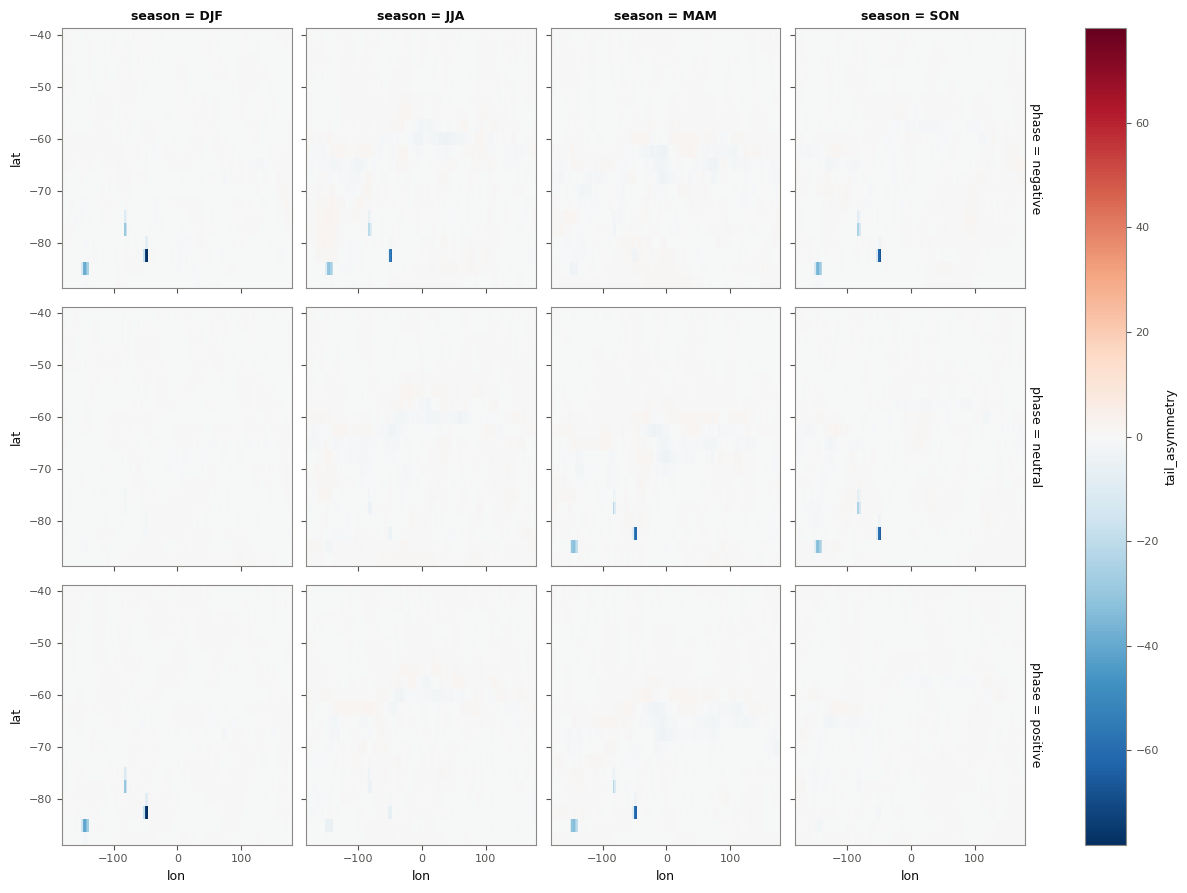

In [283]:
#(t): Quick look: DEMO_MODEL's tail asymmetry in each phase, DEMO_EXPERIMENT
sam_tails_ds['tail_asymmetry'].sel(model=DEMO_MODEL, experiment=DEMO_EXPERIMENT).plot(
    x='lon', y='lat', row='phase', col='season', cmap='RdBu_r', center=0);

## 5. Zonal Means of the Width: the Change at Each Latitude

Bracegirdle et al. (2024, *npj Clim. Atmos. Sci.* 7, 276) show the change in the low extremes, the mean, the high extremes and the width between them against latitude, averaged round the pole, with the sea-ice edge marked. Notebook plot_03 (section 7) draws the same from the changes above, for every model on its own. This section tests the zonal mean of the width with the test used for the maps, from what section 2 already made; notebook calc_02b (section 4) tests the zonal mean of the mean.

The hist-nat bootstrap trials of section 2 serve again. Trial $k$'s change at each point is its width minus hist-nat's over the same years, and averaged over longitude $\lambda$ it is one draw of what natural variability alone does to the zonal-mean width:

$$
\overline{\Delta W}_k(\varphi) = \frac{1}{N_\lambda} \sum_{\lambda} \left(W_k(\varphi, \lambda) - W^{\mathrm{nat}}(\varphi, \lambda)\right), \qquad k = 1, \ldots, N,
$$

and the observed $\overline{\Delta W}_{\mathrm{obs}}(\varphi)$ is compared with these trials as before. Averaging over longitude cancels much of the noise, so a zonal-mean change can be significant where few single points are.

The zonal-mean width is the average of the *local* widths (how much a season varies at each point), not the width of the zonal-mean series, in which anomalies at different longitudes would cancel. The low and high extremes have no test of their own.

In [288]:
#(t): The zonal-mean change in width (section 2)
zonal_width_change_da = zonal.zonal_mean(qrange_change_da)

In [289]:
#(t): The zonal mean of every bootstrap trial's change (section 2): the zonal-mean null
zonal_null_da = zonal.zonal_mean(qrange_null_da)

In [290]:
%%time
#(t): The two-sided p-value of every experiment's zonal-mean change against its model's trials
zonal_width_pvalue_da = sig.pvalue_two_sided(zonal_null_da, zonal_width_change_da).compute()

CPU times: user 21.9 ms, sys: 1.77 ms, total: 23.6 ms
Wall time: 491 ms


In [291]:
%%time
#(t): The central 1 - ALPHA of the zonal-mean trials
zonal_null_bounds_da = nan_quantile(zonal_null_da, [ALPHA / 2, 1 - ALPHA / 2], 'trial').compute()

CPU times: user 8.27 ms, sys: 1.07 ms, total: 9.34 ms
Wall time: 196 ms


In [292]:
#(t): hist-nat's zonal-mean width over the final years
zonal_hist_nat_width_da = zonal.zonal_mean(hist_nat_qrange_da)

In [293]:
#(t): The zonal width test in one Dataset, laid out as notebook plot_03 opens it
zonal_width_ds = xr.Dataset({
    'width_change': zonal_width_change_da,
    'width_pvalue': zonal_width_pvalue_da,
    'hist_nat_width': zonal_hist_nat_width_da,
    'null_lower': zonal_null_bounds_da.isel(quantile=0, drop=True),
    'null_upper': zonal_null_bounds_da.isel(quantile=1, drop=True),
})
zonal_width_ds

<xarray.Dataset> Size: 43kB
Dimensions:         (model: 6, experiment: 4, season: 4, lat: 20)
Coordinates:
  * model           (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment      (experiment) object 32B 'hist-GHG' ... 'historical'
  * season          (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat             (lat) float64 160B -87.5 -85.0 -82.5 ... -45.0 -42.5 -40.0
Data variables:
    width_change    (lat, season, model, experiment) float64 15kB -0.1202 ......
    width_pvalue    (lat, season, model, experiment) float64 15kB 0.6394 ... ...
    hist_nat_width  (lat, season, model) float64 4kB 3.305 4.164 ... 1.346 1.212
    null_lower      (lat, season, model) float64 4kB -0.3022 ... -0.04367
    null_upper      (lat, season, model) float64 4kB 0.2413 0.2274 ... 0.02441

In [295]:
#(t): Saved for notebooks plot_03 to plot_06
zonal_width_test_path = RESULTS_DIR / 'zonal_width_test.zarr'
zonal_width_ds.to_zarr(zonal_width_test_path, mode='w')
zonal_width_test_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/zonal_width_test.zarr')

In [ ]:
#(t): Quick look: DEMO_MODEL's zonal-mean change in width, one line per experiment, one panel per season
zonal_width_ds['width_change'].sel(model=DEMO_MODEL).plot.line(x='lat', hue='experiment', col='season');

## 6. Additivity of the Width (on the Variance)

Notebook calc_02b (section 3) checks whether the single forcings' changes in the mean add up to historical's. Widths do not add up, but variances do, if the forcings' contributions are independent: the variance of a sum of independent parts is the sum of their variances. So the additivity of the variability is tested on the variance of the internal variability (`qrange_tree`, section 2), each experiment's change from its own 1850–1900 baseline as in calc_02b's section 3, members and years pooled:

$$
\Delta\sigma^2_e = \sigma^2\left(x'^{\,e}_{\text{final } L \text{ years}}\right) - \sigma^2\left(x'^{\,e}_{1850\text{–}1900}\right),
\qquad
\text{residual} = \Delta\sigma^2_{\mathrm{historical}} - \left(\Delta\sigma^2_{\mathrm{nat}} + \Delta\sigma^2_{\mathrm{GHG}} + \Delta\sigma^2_{\mathrm{aer}} + \Delta\sigma^2_{\mathrm{O_3}}\right).
$$

The residual mixes three things: interaction between the forcings, forcings the four leave out (land use), and sampling noise from the ensembles' sizes.

In [430]:
#(t): The internal variability of every experiment over its own 1850-1900 baseline (qrange_tree: section 2)
internal_baseline_tree = qrange_tree.sel(year=slice(1850, 1900))

In [431]:
%%time
#(t): Its variance, members and years pooled
baseline_variance_ds = datatree.reduce_to_dataset(internal_baseline_tree,
                                                  lambda ds: ds.var(['member', 'year'], ddof=1)).compute()

CPU times: user 85.1 ms, sys: 12.1 ms, total: 97.2 ms
Wall time: 1.6 s


In [432]:
%%time
#(t): The variance over the final WINDOW years (qrange_final_tree: section 2)
final_variance_ds = datatree.reduce_to_dataset(qrange_final_tree,
                                               lambda ds: ds.var(['member', 'year'], ddof=1)).compute()

CPU times: user 85.2 ms, sys: 9.15 ms, total: 94.4 ms
Wall time: 1.15 s


In [433]:
#(t): Each experiment's change in variance from its own baseline
own_variance_changes_da = (final_variance_ds - baseline_variance_ds)[VARIABLE.name].rename('own_variance_change')
own_variance_changes_da

<xarray.DataArray 'own_variance_change' (lat: 20, lon: 144, season: 4,
                                         model: 6, experiment: 5)> Size: 3MB
0.007232 -0.042 -0.01318 0.01376 ... -0.01057 -0.002323 -0.005957 0.01239
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0

In [434]:
#(t): Saved for notebooks plot_03 to plot_06
own_variance_changes_path = RESULTS_DIR / 'own_variance_changes.zarr'
own_variance_changes_da.to_dataset(name='own_variance_change').to_zarr(own_variance_changes_path, mode='w')
own_variance_changes_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/own_variance_changes.zarr')

In [ ]:
#(t): Does historical's change in variance equal the sum of the single forcings'? (rc.additivity, as in notebook calc_02b, section 3)
variance_additivity_ds = rc.additivity(own_variance_changes_da)
variance_additivity_ds

In [436]:
#(t): Quick look: DEMO_MODEL's terms as area means south of 60°S (°C²)
sig.area_mean(variance_additivity_ds['response'].sel(model=DEMO_MODEL, lat=slice(None, -60))).to_pandas().round(3)

season,DJF,JJA,MAM,SON
term,,,,
hist-nat,0.001,-0.038,-0.131,-0.032
hist-GHG,-0.122,-0.775,-0.918,-0.186
hist-aer,0.028,0.212,0.241,0.000
hist-totalO3,-0.018,-0.113,-0.247,-0.102
sum of parts,-0.112,-0.715,-1.055,-0.321
historical,-0.102,-0.636,-0.973,-0.187
residual,0.010,0.079,0.082,0.133


## Saved Results

Everything this notebook saved, in `RESULTS_DIR`:

In [437]:
#(t): Everything this notebook saved in RESULTS_DIR
RESULTS_DIR, sorted(path.name for path in RESULTS_DIR.glob('*.zarr'))

(PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full'),
 ['anomaly_ranks.zarr',
  'demo_anomaly_ranks.zarr',
  'demo_detrended_ranks.zarr',
  'demo_plume.zarr',
  'demo_statistics.zarr',
  'demo_tests.zarr',
  'detections.zarr',
  'detrended_ranks.zarr',
  'era5_kurtosis.zarr',
  'era5_lower_tail.zarr',
  'era5_mean.zarr',
  'era5_point.zarr',
  'era5_regional.zarr',
  'era5_regional_trend.zarr',
  'era5_skewness.zarr',
  'era5_std.zarr',
  'era5_trend.zarr',
  'era5_upper_tail.zarr',
  'era5_width.zarr',
  'eval_map_table.zarr',
  'eval_table.zarr',
  'experiment_noise.zarr',
  'final_mean.zarr',
  'final_quantiles.zarr',
  'first_look.zarr',
  'forced.zarr',
  'hist_nat_final_quantiles.zarr',
  'histnat_point.zarr',
  'historical_kurtosis.zarr',
  'historical_lower_tail.zarr',
  'historical_mean.zarr',
  'historical_point.zarr',
  'historical_skewness.zarr',
  'historical_std.zarr',
  'historical_trend.zarr',
  'historical_upper_tail.zarr',
  'historical_width.zarr',
  'mean_